# LATENT DIRICHLET ALLOCATION ANALYSIS ON ABSTRACT TEXT DATA

***INTRODUCTION:*** 
    In this notebook, Latent Dirichlet Allocatin algorithm is used to model topics from the abstract dataset scraped from Scopus Citation database.

***Importation of Libraries Used for This Analysis***

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
import os
from wordcloud import WordCloud
import matplotlib.pyplot as plt


***Data Preprocessing***

In [2]:

SC_df = pd.read_csv(r"C:\Users\Derek\Scopus scrapes\Filtered_abstract.csv")

In [3]:
SC_df.shape


(2140, 6)

In [4]:
SC_df.head(5)

,Title,Abstract,Authors,Citations,Year,Country Affiliation
0,SMS Marketing: An emergent trend within SMEs,This chapter seeks to extend current knowledge...,Takhar A.,1,2013,South Africa
1,Selection of market entry strategies: Perspect...,The purpose of this chapter is to investigate ...,Chanakira M.,0,2013,Zimbabwe
2,Computational intelligence in remanufacturing,In attempts to reduce greenhouse gas emissions...,Xing B.,7,2013,South Africa
3,An overview of e-government technological divi...,This chapter presents an overview of e-Governm...,Oyekunle R.A.,0,2013,Nigeria
4,A semantic-enabled framework for e-government ...,The ultimate goal of e-Governance is to reach ...,Fonou-Dombeu J.V.,0,2013,"South Africa, South Africa"


***CountVectorizer Code for Document-Term Matrix (DTM)***
The provided code below uses the CountVectorizer class to create a document-term matrix (DTM) from text data. It sets parameters such as maximum and minimum document frequency for token inclusion, and removal of English stop words. The fit_transform method is applied to the 'Abstract' column of a DataFrame to generate the DTM stored in the variable dtm.

In [5]:
cv = CountVectorizer(max_df=0.95, min_df=2, stop_words="english")
dtm = cv.fit_transform(SC_df['Abstract'])
dtm

<2140x12523 sparse matrix of type '<class 'numpy.int64'>'
	with 198078 stored elements in Compressed Sparse Row format>

In [6]:
feature_names = cv.get_feature_names_out()
len(feature_names) # show the total number of distinct words

12523

In [7]:
#Let's have a look at some of the features that have been extracted from the documents
feature_names[12500:]

array(['zircons', 'zn', 'zno', 'zns', 'zone', 'zones', 'zoonosis',
       'zoonotic', 'zooplankton', 'zp', 'zr', 'zulu', 'µg', 'µm', 'α1',
       'β1', 'δ13c', 'δ15n', 'μg', 'μl', 'μm', 'μmol', 'χ2'], dtype=object)

# BUILDING AN LDA MODEL

LDA From our DTM matrix, we can now build our LDA to extract topics from the underlined texts. The number of topic to be extracted is a hyperparameter, so we do not know it a a glance. In our case, we will be using 10 topics. LDA is an iterative algorithm, we will have 30 iterations in our case, but the default value is 10.

In [8]:
from gensim.models import LdaModel
from gensim.corpora import Dictionary
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
import pandas as pd
import gensim.downloader as api
import re
# Download NLTK stopwords
import nltk
nltk.download('stopwords')

# Define common keywords to be removed
common_keywords = ['study', 'data', 'analysis', 'results', 'results', 'literature', 'conclusion','background','aor','method', 'studies','methods','aim','methodology','using','used', 'use','also', 'background', 'one','two', 'among','research','however','including', 'may','new']  # Add more words as needed

stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    tokens = word_tokenize(str(text).lower())
    tokens = [token for token in tokens if token.isalpha() and token not in stop_words]
    
    # Remove common keywords
    tokens = [token for token in tokens if token not in common_keywords]
    
    # Debugging: print tokens after preprocessing
    print("Tokens after preprocessing:", tokens)
    
    return tokens if tokens else ['N/A']  # If the list is empty, return a placeholder value


# Apply preprocessing to the 'Abstract' column
if 'Abstract' in SC_df.columns:
    SC_df['processed_Abstract'] = SC_df['Abstract'].apply(preprocess_text)
else:
    print("Error: 'Abstract' column not found in DataFrame.")

# Filter out rows where 'processed_Abstract' is 'N/A'
SC_df = SC_df[SC_df['processed_Abstract'].apply(lambda x: x != ['N/A'])]

# Create a Gensim Dictionary
dictionary = Dictionary(SC_df['processed_Abstract'])

# Create a Gensim Corpus
corpus = [dictionary.doc2bow(text) for text in SC_df['processed_Abstract']]

# Train an LDA model
lda_model = LdaModel(corpus, num_topics=27, id2word=dictionary, passes=55)

# Get topics for each document
topics = lda_model.get_document_topics(corpus)

# Add the topics to the DataFrame
SC_df['lda_topics'] = [max(topic, key=lambda x: x[1])[0] for topic in topics]

# Save the DataFrame to a CSV file
SC_df.to_csv('lda_topics_output.csv', index=False)

# Display the DataFrame with LDA topics
SC_df[['Title', 'Abstract', 'Authors', 'Country Affiliation', 'Citations', 'lda_topics']]


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Derek\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Tokens after preprocessing: ['chapter', 'seeks', 'extend', 'current', 'knowledge', 'relating', 'innovative', 'marketing', 'authors', 'consider', 'significance', 'sms', 'marketing', 'amongst', 'small', 'medium', 'enterprises', 'smes', 'within', 'south', 'africa', 'emphasise', 'various', 'advantages', 'sms', 'marketing', 'smes', 'within', 'emerging', 'economies', 'look', 'sms', 'marketing', 'emerged', 'within', 'western', 'world', 'could', 'successful', 'emerging', 'economies', 'different', 'factors', 'considered', 'sms', 'marketing', 'sms', 'marketing', 'entails', 'trends', 'sms', 'marketing', 'globally', 'specifically', 'within', 'south', 'africa', 'authors', 'discuss', 'emergent', 'key', 'themes', 'sms', 'marketing', 'relating', 'beneficial', 'characteristics', 'cost', 'efficiency', 'reach', 'consumer', 'perceptions', 'findings', 'offer', 'significant', 'insight', 'smes', 'better', 'understand', 'consumer', 'perceptions', 'sms', 'turn', 'employ', 'sms', 'marketing', 'source', 'sustain

Tokens after preprocessing: ['marjoram', 'origanum', 'majorana', 'plants', 'treated', 'different', 'concentrations', 'herbicides', 'herbicide', 'plants', 'sprayed', 'times', 'vegetative', 'stage', 'flowering', 'stage', 'throughout', 'stages', 'plant', 'growth', 'showed', 'growth', 'parameters', 'plant', 'height', 'cm', 'number', 'number', 'lateral', 'number', 'fresh', 'dry', 'weights', 'plant', 'leaves', 'increased', 'treated', 'plant', 'samples', 'herbicides', 'compared', 'control', 'estimation', 'protein', 'showed', 'significant', 'variation', 'protein', 'profile', 'herbicides', 'treatments', 'increase', 'number', 'polypeptide', 'bands', 'total', 'amount', 'protein', 'compared', 'non', 'treated', 'control', 'detected', 'presence', 'number', 'polypeptide', 'bands', 'herbicides', 'treated', 'samples', 'forming', 'defence', 'strategy', 'herbicide', 'stress', 'compared', 'control', 'essential', 'volatile', 'oils', 'gas', 'chromatography', 'gc', 'revealed', 'presence', 'components', 'iden

Tokens after preprocessing: ['cervical', 'cancer', 'leading', 'cause', 'cancer', 'morbidity', 'mortality', 'women', 'africa', 'ssa', 'accounting', 'deaths', 'annually', 'recently', 'cytology', 'gold', 'standard', 'screening', 'prevention', 'cervical', 'cancer', 'screening', 'successful', 'ssa', 'due', 'lack', 'human', 'financial', 'material', 'resources', 'poor', 'health', 'care', 'infrastructure', 'estimated', 'less', 'risk', 'women', 'ever', 'screened', 'past', 'decades', 'alternative', 'approaches', 'cytology', 'cervical', 'cancer', 'screening', 'evaluated', 'countries', 'visual', 'inspection', 'acetic', 'acid', 'via', 'lugol', 'iodine', 'vili', 'shown', 'adequate', 'sensitivity', 'although', 'low', 'specificity', 'number', 'demonstration', 'projects', 'visual', 'inspection', 'require', 'minimal', 'resources', 'technologically', 'accessible', 'feasible', 'screening', 'precancerous', 'lesions', 'linking', 'screening', 'treatment', 'cryotherapy', 'enable', 'screening', 'treatment', 't

Tokens after preprocessing: ['cassava', 'genetic', 'transformation', 'capacity', 'still', 'mostly', 'restricted', 'advanced', 'laboratories', 'usa', 'europe', 'china', 'implementation', 'maintenance', 'african', 'laboratories', 'remained', 'scarce', 'impact', 'transgenic', 'technologies', 'genetic', 'improvement', 'cassava', 'depend', 'largely', 'transfer', 'capabilities', 'researchers', 'africa', 'cassava', 'important', 'socioeconomic', 'niche', 'major', 'constraint', 'development', 'genetic', 'transformation', 'technologies', 'cassava', 'improvement', 'lack', 'efficient', 'robust', 'transformation', 'regeneration', 'system', 'despite', 'success', 'achieved', 'genetic', 'modification', 'cassava', 'cultivars', 'model', 'cultivar', 'transgenic', 'cassava', 'production', 'remains', 'difficult', 'cultivars', 'protocol', 'cultivar', 'developed', 'eth', 'zurich', 'successfully', 'implemented', 'optimized', 'establish', 'transformation', 'cassava', 'cultivars', 'popular', 'east', 'africa', '

Tokens after preprocessing: ['introduction', 'highly', 'active', 'antiretroviral', 'therapy', 'haart', 'led', 'significant', 'improvement', 'survival', 'patient', 'effects', 'quality', 'life', 'hrqol', 'less', 'known', 'assess', 'temporal', 'changes', 'factors', 'associated', 'hrqol', 'adults', 'initiating', 'haart', 'burkina', 'faso', 'people', 'initiating', 'haart', 'prospectively', 'included', 'followed', 'period', 'three', 'hiv', 'clinics', 'ouagadougou', 'hrqol', 'assessed', 'baseline', 'visit', 'physical', 'phs', 'mental', 'mhs', 'summary', 'scores', 'derived', 'medical', 'outcome', 'health', 'survey', 'mos', 'questionnaire', 'toxicity', 'related', 'haart', 'modification', 'symptoms', 'recorded', 'visits', 'determinants', 'associated', 'baseline', 'changes', 'scores', 'period', 'assessed', 'mixed', 'linear', 'model', 'total', 'patients', 'included', 'median', 'age', 'baseline', 'years', 'interquartile', 'range', 'iqr', 'median', 'count', 'iqr', 'mean', 'standard', 'deviation', 's

... (37 outputs left out)

Tokens after preprocessing: ['rwanda', 'prevalent', 'livestock', 'farming', 'activity', 'carried', 'improve', 'livelihoods', 'rural', 'areas', 'poultry', 'farming', 'common', 'bird', 'species', 'raised', 'egg', 'meat', 'production', 'indigenous', 'chicken', 'ic', 'despite', 'economic', 'significance', 'improvement', 'programs', 'rwanda', 'given', 'ic', 'little', 'attention', 'therefore', 'little', 'documentation', 'production', 'disease', 'resistance', 'performance', 'aimed', 'evaluating', 'growth', 'performance', 'immunologic', 'response', 'ic', 'newcastle', 'disease', 'vaccine', 'four', 'gene', 'pools', 'rwanda', 'hundred', 'ic', 'four', 'gene', 'pools', 'kept', 'completely', 'randomized', 'design', 'thereafter', 'ic', 'vaccinated', 'live', 'commercial', 'newcastle', 'disease', 'virus', 'body', 'weight', 'collected', 'weekly', 'weeks', 'whereas', 'serum', 'samples', 'collected', 'days', 'antibody', 'responses', 'determined', 'indirect', 'elisa', 'variance', 'performed', 'sas', 'gener

Tokens after preprocessing: ['dermal', 'leishmaniasis', 'pkdl', 'rare', 'skin', 'syndrome', 'observed', 'treatment', 'visceral', 'leishmaniasis', 'vl', 'pentavalent', 'antimonial', 'organic', 'salts', 'never', 'described', 'morocco', 'report', 'case', 'immunocompetent', 'adult', 'case', 'tata', 'southern', 'morocco', 'history', 'visceral', 'leishmaniasis', 'years', 'treated', 'meglumine', 'antimoniate', 'amphotericin', 'b', 'good', 'clinical', 'course', 'hospitalized', 'dermatology', 'erythematous', 'closet', 'face', 'six', 'months', 'ago', 'presented', 'oral', 'mucosa', 'involvement', 'months', 'later', 'cutaneous', 'lesions', 'appeared', 'face', 'dermatological', 'examination', 'revealed', 'erythematous', 'closet', 'extending', 'nose', 'cheeks', 'crusty', 'lupoid', 'lesions', 'forehead', 'around', 'eyes', 'chin', 'associated', 'ulcerative', 'painless', 'lesion', 'heel', 'examination', 'oral', 'mucosa', 'revealed', 'ulceration', 'posterior', 'third', 'tongue', 'papillomatous', 'aspect

Tokens after preprocessing: ['local', 'government', 'south', 'africa', 'crisis', 'situation', 'getting', 'worse', 'majority', 'municipalities', 'experiencing', 'serious', 'issues', 'poor', 'service', 'delivery', 'limited', 'provision', 'maintenance', 'inadequate', 'financial', 'management', 'measurement', 'municipal', 'financial', 'health', 'growing', 'field', 'several', 'measurement', 'tools', 'developed', 'last', 'decades', 'existing', 'indexes', 'succeeded', 'comprehensively', 'capturing', 'full', 'extent', 'financial', 'management', 'local', 'government', 'sphere', 'measurement', 'financial', 'health', 'important', 'order', 'track', 'compare', 'performance', 'municipalities', 'objective', 'apply', 'financial', 'health', 'index', 'fhi', 'developed', 'authors', 'eight', 'metropolitan', 'municipalities', 'south', 'africa', 'fhi', 'focuses', 'four', 'namely', 'income', 'expenditure', 'liquidity', 'ratios', 'ratios', 'profitability', 'ratios', 'fhi', 'obtained', 'local', 'government', '

,Title,Abstract,Authors,Country Affiliation,Citations,lda_topics
0,SMS Marketing: An emergent trend within SMEs,This chapter seeks to extend current knowledge...,Takhar A.,South Africa,1,2
1,Selection of market entry strategies: Perspect...,The purpose of this chapter is to investigate ...,Chanakira M.,Zimbabwe,0,4
2,Computational intelligence in remanufacturing,In attempts to reduce greenhouse gas emissions...,Xing B.,South Africa,7,2
3,An overview of e-government technological divi...,This chapter presents an overview of e-Governm...,Oyekunle R.A.,Nigeria,0,16
4,A semantic-enabled framework for e-government ...,The ultimate goal of e-Governance is to reach ...,Fonou-Dombeu J.V.,"South Africa, South Africa",0,24
...,...,...,...,...,...,...
2135,The Zimbabwe Culture and the development of th...,A multi-disciplinary research project in north...,Shenjere-Nyabezi P.,"Zimbabwe, South Africa",0,12
2136,Short and intermediate outcome of endovascular...,BACKGROUND: The availability of aortic stent-g...,Sayed M.H.,Egypt,0,26
2137,Fecal markers of environmental enteric dysfunc...,BACKGROUND: Chronic malnutrition is a long-ter...,El Wakeel M.A.,"Egypt, Egypt",2,18
2138,One-year outcome of different unprotected left...,BACKGROUND: Percutaneous coronary intervention...,Elhadidy A.,Egypt,0,6


In [9]:
SC_df = pd.read_csv(r"C:\Users\Derek\scopus data anal\DissertationPython Files\lda_topics_output.csv")

In [10]:
pd.set_option('display.max_colwidth', None)
SC_df

,Title,Abstract,Authors,Citations,Year,Country Affiliation,processed_Abstract,lda_topics
0,SMS Marketing: An emergent trend within SMEs,"This chapter seeks to extend current knowledge relating to innovative methods in marketing. The authors consider the significance of SMS marketing amongst Small and Medium Enterprises (SMEs) within South Africa and aim to emphasise the various advantages of SMS marketing to SMEs within emerging economies. They look at how SMS marketing has emerged within the Western world and how it could be just as successful in emerging economies. Different factors are considered such as the background to SMS marketing, what SMS marketing entails, the trends of SMS marketing globally and more specifically within South Africa. The authors then discuss the emergent key themes of SMS marketing relating to its most beneficial characteristics such as cost efficiency, reach, and consumer perceptions. The findings offer significant insight into how SMEs can better understand consumer perceptions about SMS and in turn employ SMS marketing as a source of sustainable competitive advantage.",Takhar A.,1,2013,South Africa,"['chapter', 'seeks', 'extend', 'current', 'knowledge', 'relating', 'innovative', 'marketing', 'authors', 'consider', 'significance', 'sms', 'marketing', 'amongst', 'small', 'medium', 'enterprises', 'smes', 'within', 'south', 'africa', 'emphasise', 'various', 'advantages', 'sms', 'marketing', 'smes', 'within', 'emerging', 'economies', 'look', 'sms', 'marketing', 'emerged', 'within', 'western', 'world', 'could', 'successful', 'emerging', 'economies', 'different', 'factors', 'considered', 'sms', 'marketing', 'sms', 'marketing', 'entails', 'trends', 'sms', 'marketing', 'globally', 'specifically', 'within', 'south', 'africa', 'authors', 'discuss', 'emergent', 'key', 'themes', 'sms', 'marketing', 'relating', 'beneficial', 'characteristics', 'cost', 'efficiency', 'reach', 'consumer', 'perceptions', 'findings', 'offer', 'significant', 'insight', 'smes', 'better', 'understand', 'consumer', 'perceptions', 'sms', 'turn', 'employ', 'sms', 'marketing', 'source', 'sustainable', 'competitive', 'advantage']",2
1,Selection of market entry strategies: Perspectives from the mobile telephony industry in Africa,"The purpose of this chapter is to investigate the selection of market entry strategies in the African mobile telephony industry with a view to developing appropriate business strategies and identifying risk factors. Using the survey methodology, the study focuses on six key enterprises, which account for over 60% of mobile phones in Africa. The empirical evidence suggests that market size in terms of population of the destination country and not psychic distance is the most important market selection criteria for enterprises entering Africa. The dominant entry market strategy for these enterprises is strategic alliances. Focused strategy is uncommon on the continent. More interestingly, and contrary to extant literature, political risk was not considered a market entry barrier. In any case, politically unstable countries tend to bring in higher returns. These findings are critical in informing investors engaged in or with intentions to enter Africa and in enriching international literature. The Stages model and the DMP framework individually are unable to explain the choice of market entry strategy in Africa. The key contributions of this study are both theoretical and practical insights on the process of internationalisation.",Chanakira M.,0,2013,Zimbabwe,"['purpose', 'chapter', 'investigate', 'selection', 'market', 'entry', 'strategies', 'african', 'mobile', 'telephony', 'industry', 'view', 'developing', 'appropriate', 'business', 'strategies', 'identifying', 'risk', 'factors', 'survey', 'focuses', 'six', 'key', 'enterprises', 'account', 'mobile', 'phones', 'africa', 'empirical', 'evidence', 'suggests', 'market', 'size', 'terms', 'population', 'destination', 'country', 'psychic', 'distance', 'important', 'marke

# PLOTTING WORD CLOUD

***Now that the model has been sued to generate topics the next step is to create a word cloud to visualise the word contents for each topic***

In [11]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

def plot_wordcloud_from_df(df, column_name, max_words=200, max_font_size=100, title='', title_size=20, save_as=None):
    text = ' '.join(df[column_name].astype(str))
    wordcloud = WordCloud(max_words=max_words, max_font_size=max_font_size, background_color="white").generate(text)
    
    plt.figure(figsize=(10, 10))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.title(title, size=title_size)
    plt.axis("off")

    if save_as:
        plt.savefig(save_as, format='png', bbox_inches='tight')
        current_directory = os.getcwd()
        print(f"Word cloud saved as {save_as} in the directory: {current_directory}")

    plt.show()


Word cloud saved as wordcloud.png in the directory: C:\Users\Derek\scopus data anal\DissertationPython Files


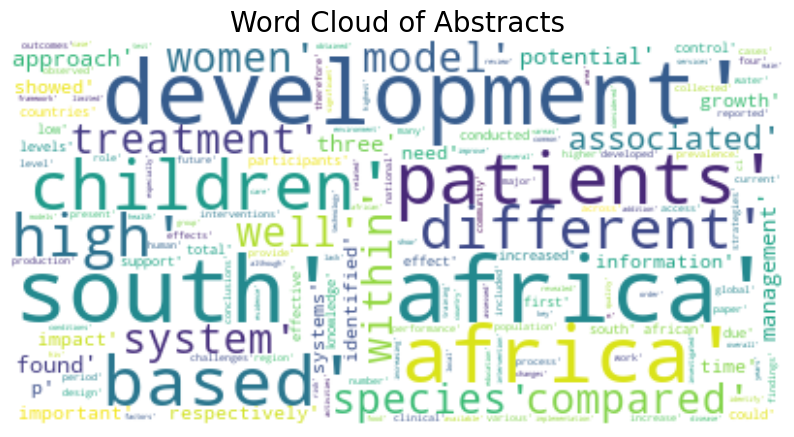

In [12]:

# Filter out rows where 'processed_Abstract' is 'N/A'
SC_df = SC_df[SC_df['processed_Abstract'].apply(lambda x: x != ['N/A'])]

# Generate word cloud from the 'processed_Abstract' column
plot_wordcloud_from_df(SC_df, 'processed_Abstract', title="Word Cloud of Abstracts", save_as="wordcloud.png")


C:\Users\Derek\AppData\Local\Temp\ipykernel_4824\96158943.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  topic_df.dropna(subset=['processed_Abstract'], inplace=True)


Word cloud saved as wordcloud_topic_0.png in the directory: C:\Users\Derek\scopus data anal\DissertationPython Files


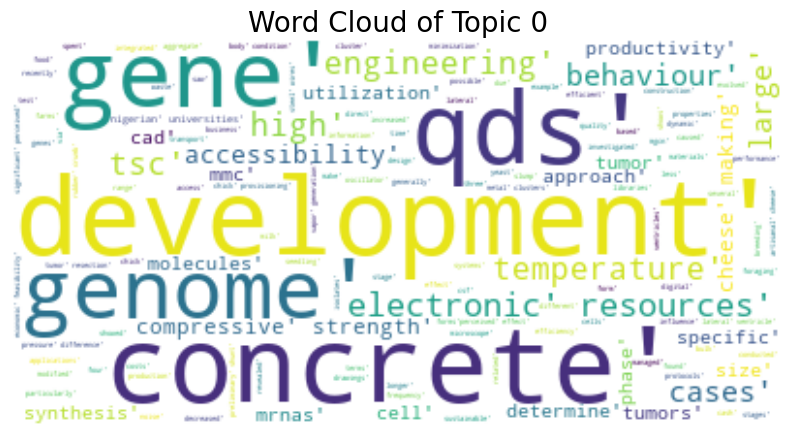

C:\Users\Derek\AppData\Local\Temp\ipykernel_4824\96158943.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  topic_df.dropna(subset=['processed_Abstract'], inplace=True)


Word cloud saved as wordcloud_topic_1.png in the directory: C:\Users\Derek\scopus data anal\DissertationPython Files


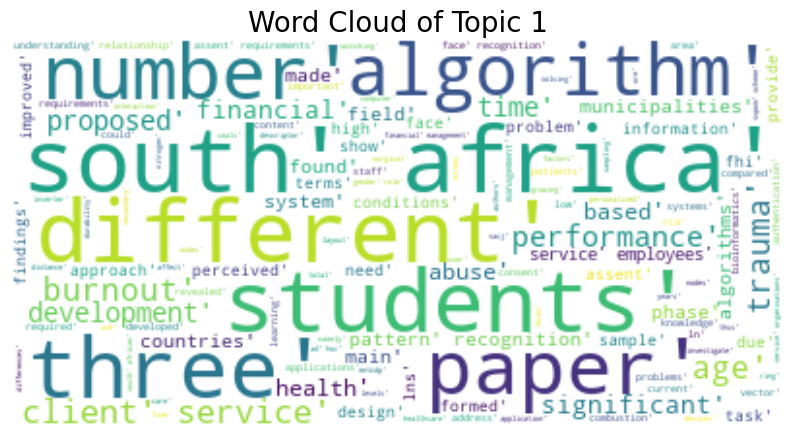

C:\Users\Derek\AppData\Local\Temp\ipykernel_4824\96158943.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  topic_df.dropna(subset=['processed_Abstract'], inplace=True)


Word cloud saved as wordcloud_topic_2.png in the directory: C:\Users\Derek\scopus data anal\DissertationPython Files


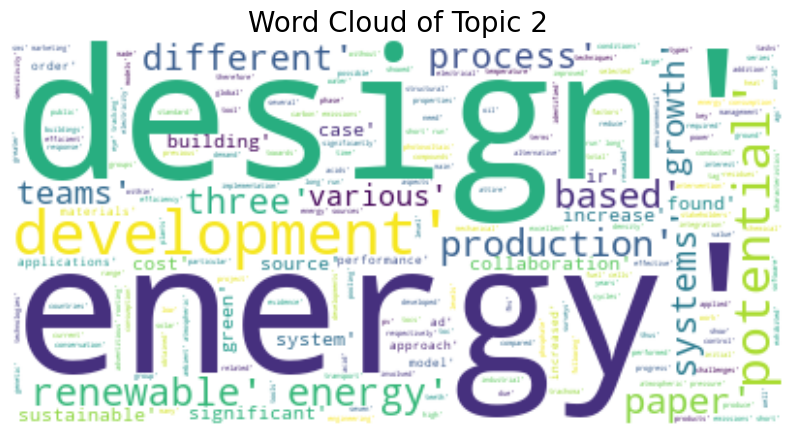

C:\Users\Derek\AppData\Local\Temp\ipykernel_4824\96158943.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  topic_df.dropna(subset=['processed_Abstract'], inplace=True)


Word cloud saved as wordcloud_topic_3.png in the directory: C:\Users\Derek\scopus data anal\DissertationPython Files


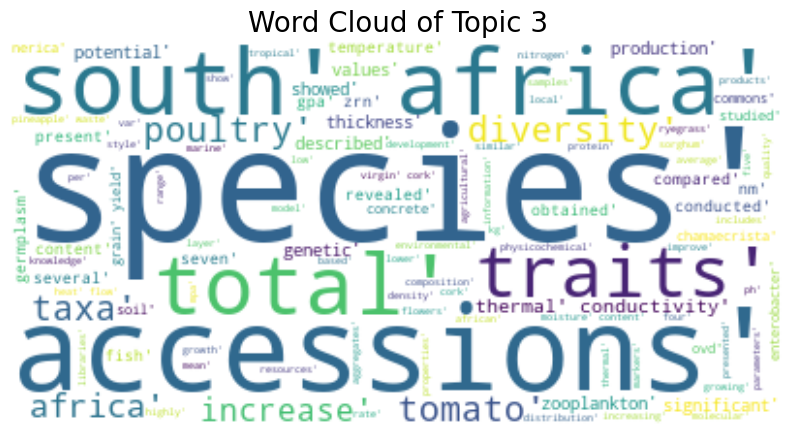

C:\Users\Derek\AppData\Local\Temp\ipykernel_4824\96158943.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  topic_df.dropna(subset=['processed_Abstract'], inplace=True)


Word cloud saved as wordcloud_topic_4.png in the directory: C:\Users\Derek\scopus data anal\DissertationPython Files


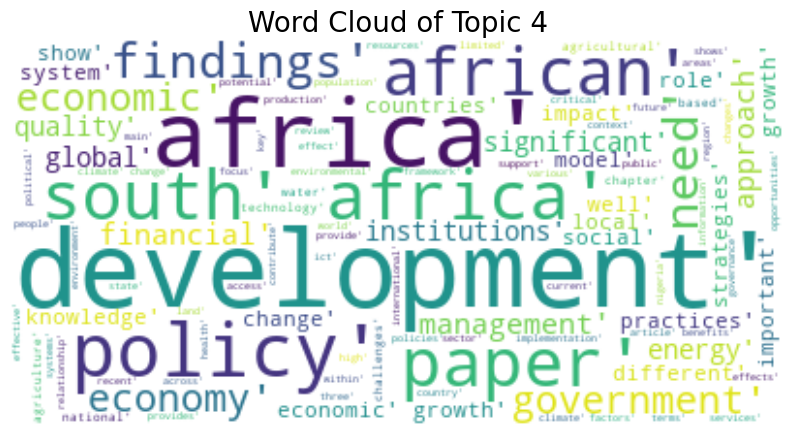

C:\Users\Derek\AppData\Local\Temp\ipykernel_4824\96158943.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  topic_df.dropna(subset=['processed_Abstract'], inplace=True)


Word cloud saved as wordcloud_topic_5.png in the directory: C:\Users\Derek\scopus data anal\DissertationPython Files


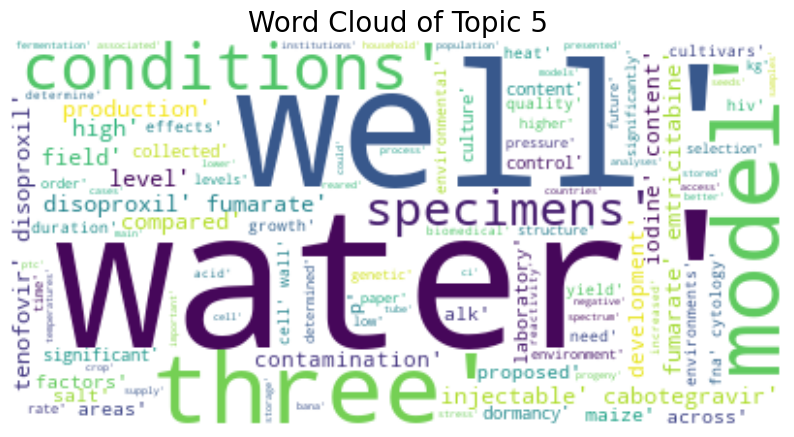

C:\Users\Derek\AppData\Local\Temp\ipykernel_4824\96158943.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  topic_df.dropna(subset=['processed_Abstract'], inplace=True)


Word cloud saved as wordcloud_topic_6.png in the directory: C:\Users\Derek\scopus data anal\DissertationPython Files


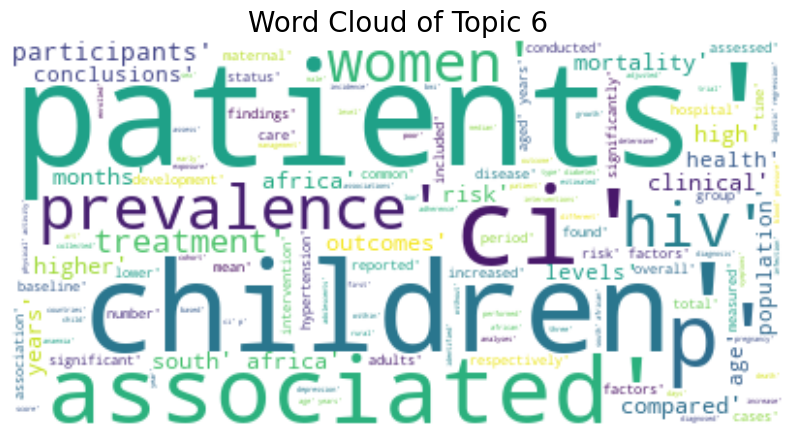

C:\Users\Derek\AppData\Local\Temp\ipykernel_4824\96158943.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  topic_df.dropna(subset=['processed_Abstract'], inplace=True)


Word cloud saved as wordcloud_topic_7.png in the directory: C:\Users\Derek\scopus data anal\DissertationPython Files


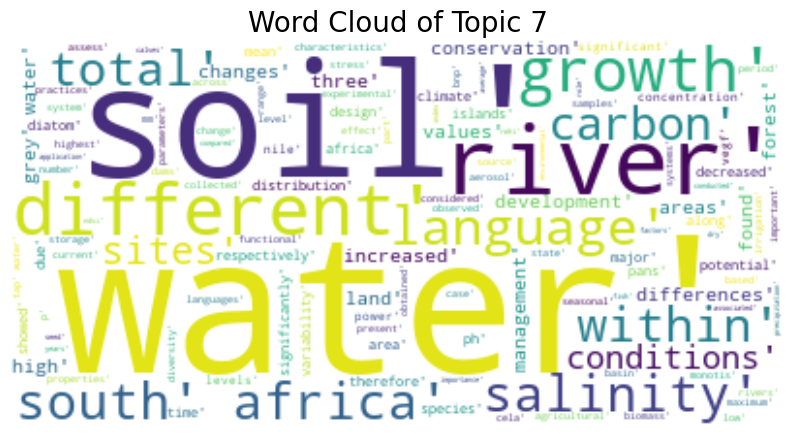

C:\Users\Derek\AppData\Local\Temp\ipykernel_4824\96158943.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  topic_df.dropna(subset=['processed_Abstract'], inplace=True)


Word cloud saved as wordcloud_topic_8.png in the directory: C:\Users\Derek\scopus data anal\DissertationPython Files


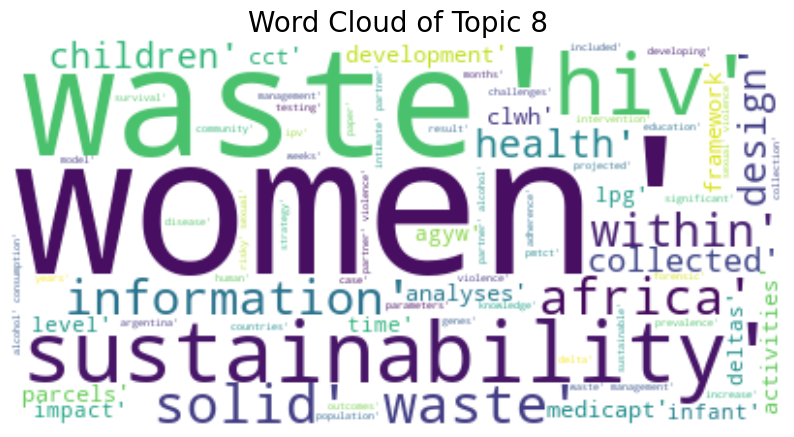

C:\Users\Derek\AppData\Local\Temp\ipykernel_4824\96158943.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  topic_df.dropna(subset=['processed_Abstract'], inplace=True)


Word cloud saved as wordcloud_topic_9.png in the directory: C:\Users\Derek\scopus data anal\DissertationPython Files


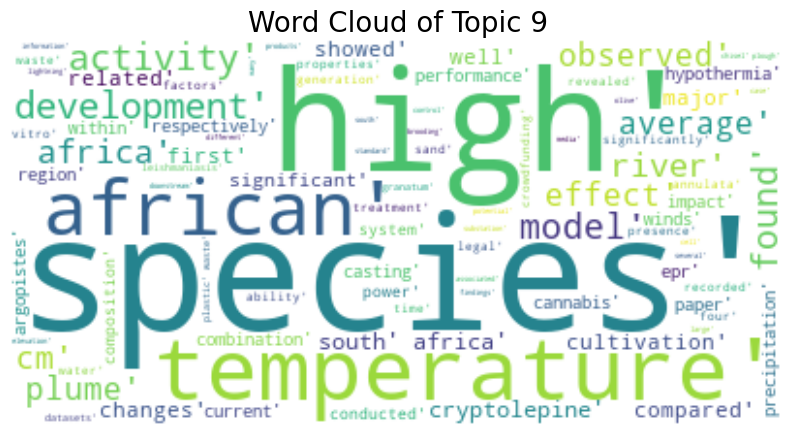

C:\Users\Derek\AppData\Local\Temp\ipykernel_4824\96158943.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  topic_df.dropna(subset=['processed_Abstract'], inplace=True)


Word cloud saved as wordcloud_topic_10.png in the directory: C:\Users\Derek\scopus data anal\DissertationPython Files


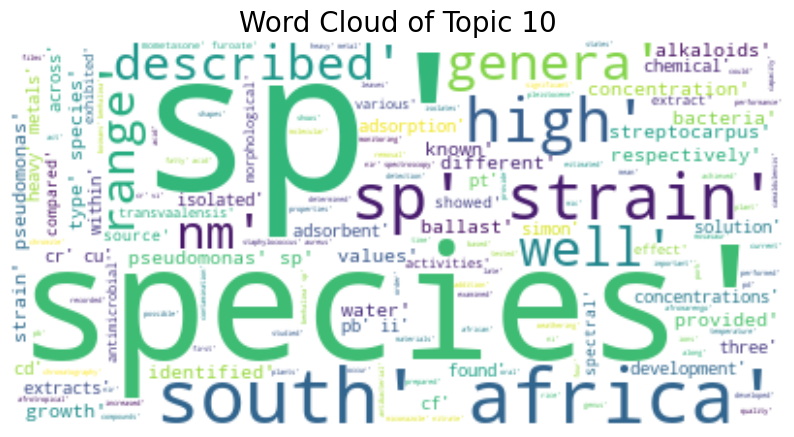

C:\Users\Derek\AppData\Local\Temp\ipykernel_4824\96158943.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  topic_df.dropna(subset=['processed_Abstract'], inplace=True)


Word cloud saved as wordcloud_topic_11.png in the directory: C:\Users\Derek\scopus data anal\DissertationPython Files


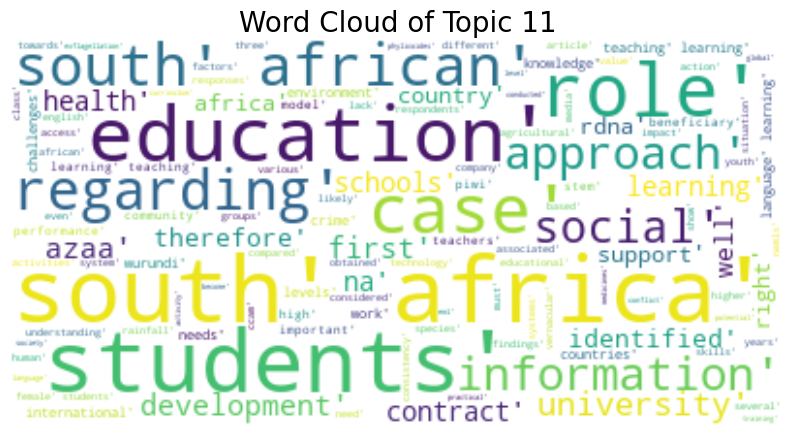

C:\Users\Derek\AppData\Local\Temp\ipykernel_4824\96158943.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  topic_df.dropna(subset=['processed_Abstract'], inplace=True)


Word cloud saved as wordcloud_topic_12.png in the directory: C:\Users\Derek\scopus data anal\DissertationPython Files


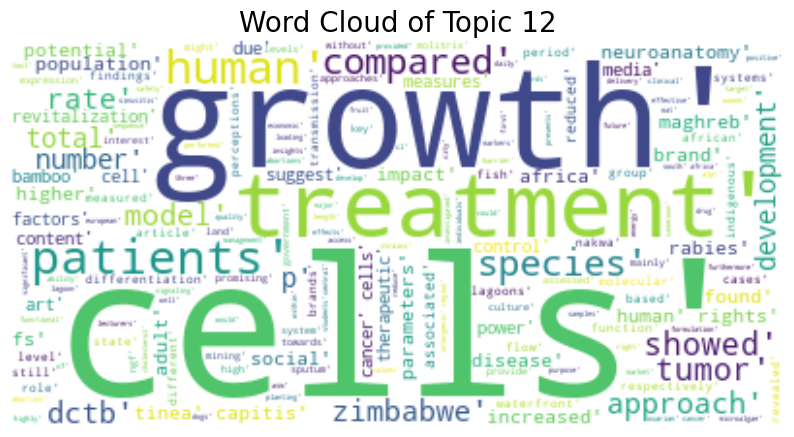

C:\Users\Derek\AppData\Local\Temp\ipykernel_4824\96158943.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  topic_df.dropna(subset=['processed_Abstract'], inplace=True)


Word cloud saved as wordcloud_topic_13.png in the directory: C:\Users\Derek\scopus data anal\DissertationPython Files


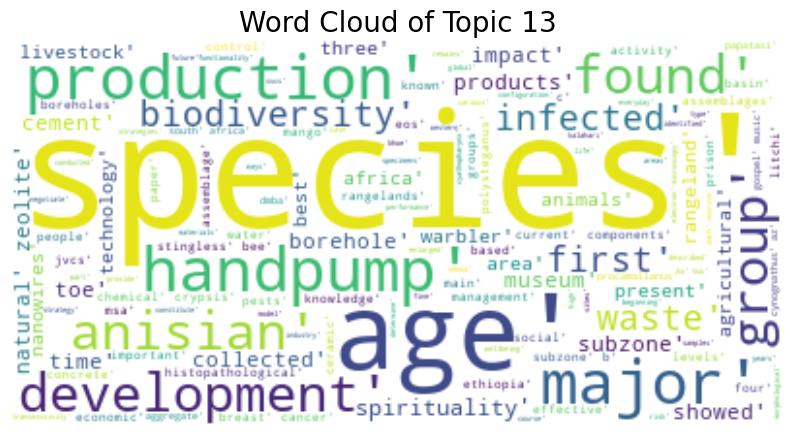

C:\Users\Derek\AppData\Local\Temp\ipykernel_4824\96158943.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  topic_df.dropna(subset=['processed_Abstract'], inplace=True)


Word cloud saved as wordcloud_topic_14.png in the directory: C:\Users\Derek\scopus data anal\DissertationPython Files


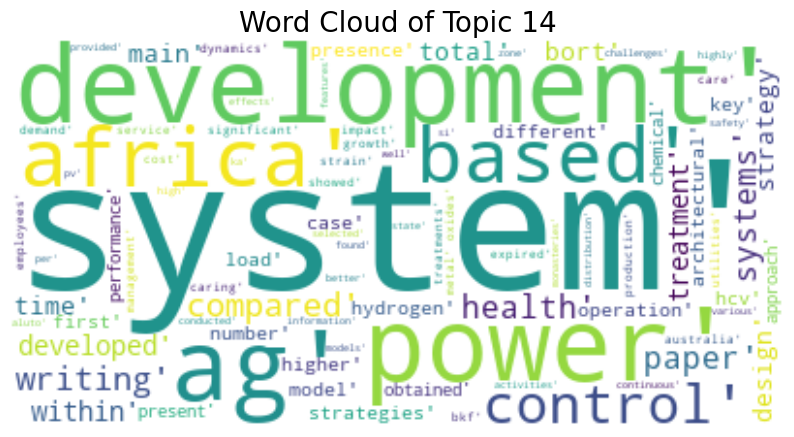

C:\Users\Derek\AppData\Local\Temp\ipykernel_4824\96158943.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  topic_df.dropna(subset=['processed_Abstract'], inplace=True)


Word cloud saved as wordcloud_topic_15.png in the directory: C:\Users\Derek\scopus data anal\DissertationPython Files


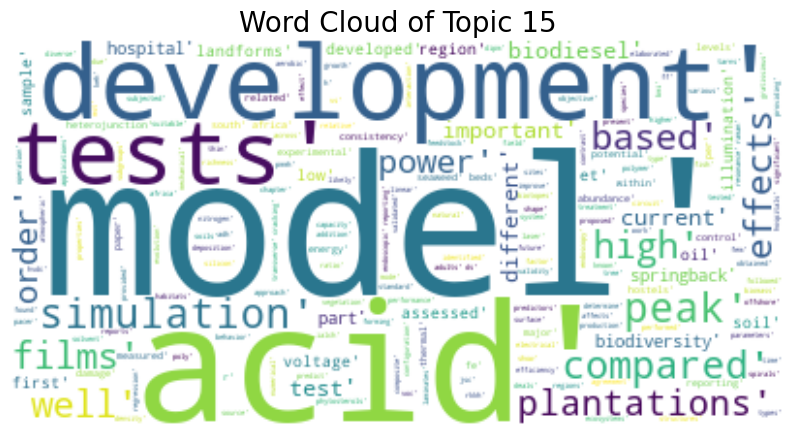

C:\Users\Derek\AppData\Local\Temp\ipykernel_4824\96158943.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  topic_df.dropna(subset=['processed_Abstract'], inplace=True)


Word cloud saved as wordcloud_topic_16.png in the directory: C:\Users\Derek\scopus data anal\DissertationPython Files


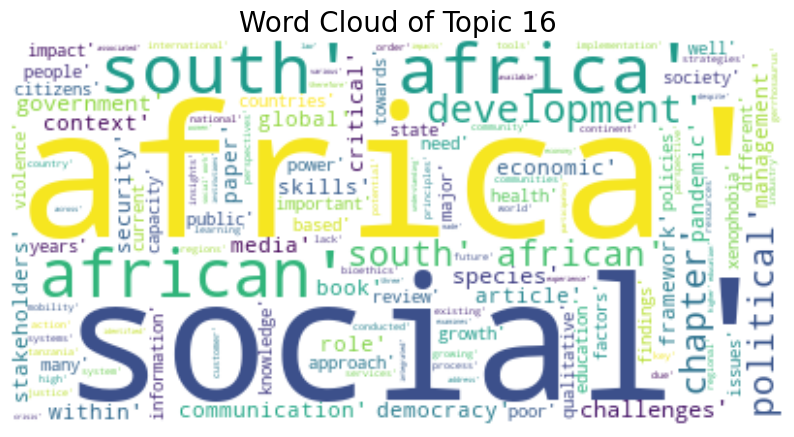

C:\Users\Derek\AppData\Local\Temp\ipykernel_4824\96158943.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  topic_df.dropna(subset=['processed_Abstract'], inplace=True)


Word cloud saved as wordcloud_topic_17.png in the directory: C:\Users\Derek\scopus data anal\DissertationPython Files


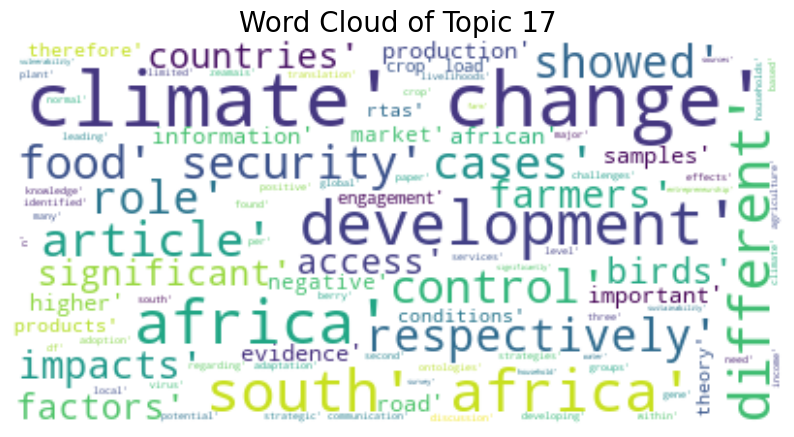

C:\Users\Derek\AppData\Local\Temp\ipykernel_4824\96158943.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  topic_df.dropna(subset=['processed_Abstract'], inplace=True)


Word cloud saved as wordcloud_topic_18.png in the directory: C:\Users\Derek\scopus data anal\DissertationPython Files


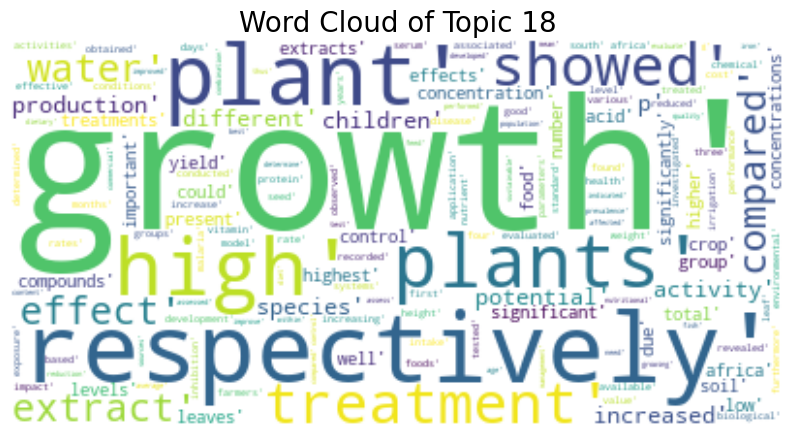

C:\Users\Derek\AppData\Local\Temp\ipykernel_4824\96158943.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  topic_df.dropna(subset=['processed_Abstract'], inplace=True)


Word cloud saved as wordcloud_topic_19.png in the directory: C:\Users\Derek\scopus data anal\DissertationPython Files


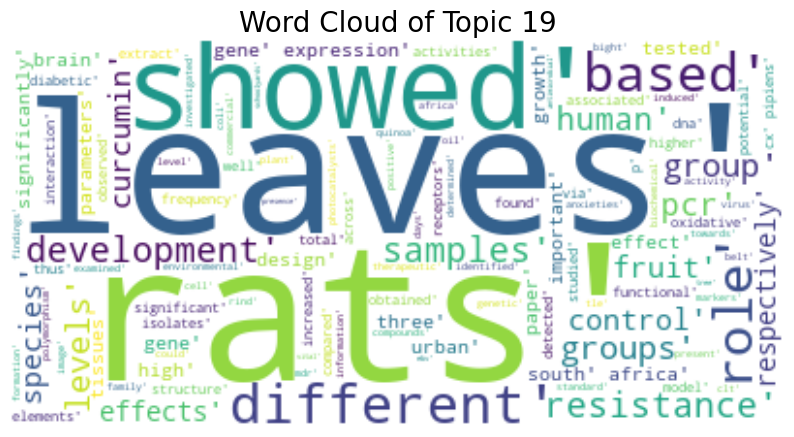

C:\Users\Derek\AppData\Local\Temp\ipykernel_4824\96158943.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  topic_df.dropna(subset=['processed_Abstract'], inplace=True)


Word cloud saved as wordcloud_topic_20.png in the directory: C:\Users\Derek\scopus data anal\DissertationPython Files


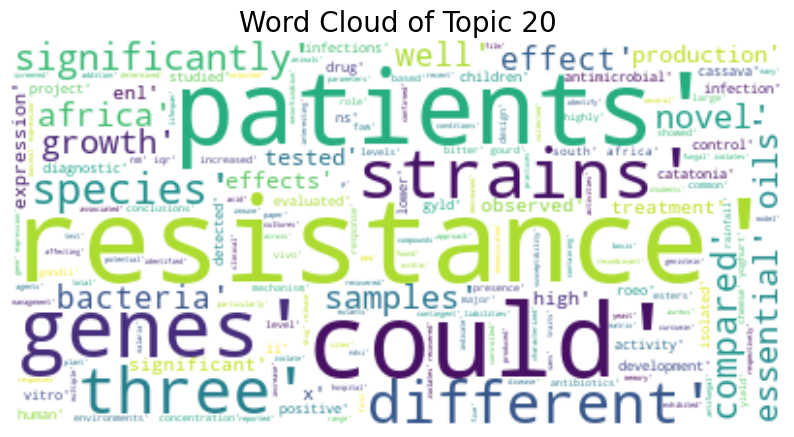

C:\Users\Derek\AppData\Local\Temp\ipykernel_4824\96158943.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  topic_df.dropna(subset=['processed_Abstract'], inplace=True)


Word cloud saved as wordcloud_topic_21.png in the directory: C:\Users\Derek\scopus data anal\DissertationPython Files


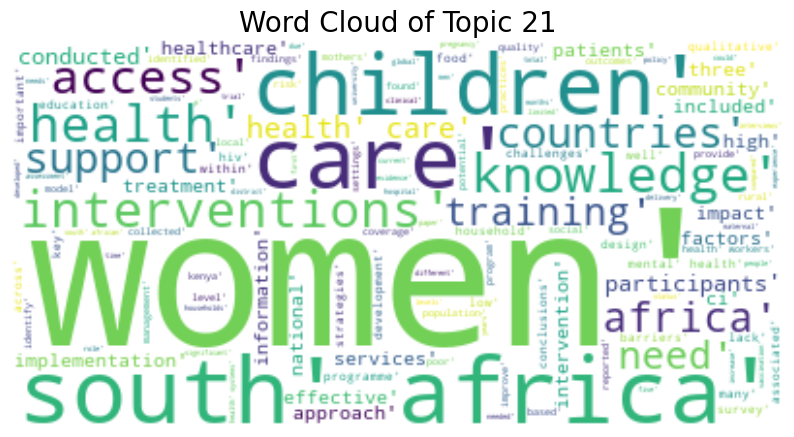

C:\Users\Derek\AppData\Local\Temp\ipykernel_4824\96158943.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  topic_df.dropna(subset=['processed_Abstract'], inplace=True)


Word cloud saved as wordcloud_topic_22.png in the directory: C:\Users\Derek\scopus data anal\DissertationPython Files


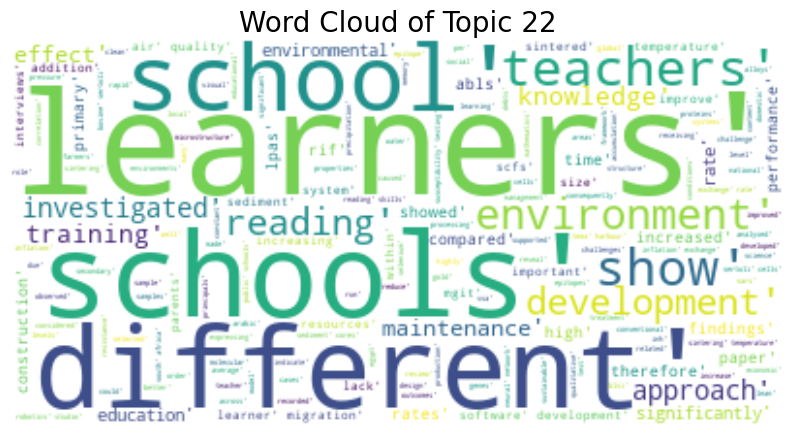

C:\Users\Derek\AppData\Local\Temp\ipykernel_4824\96158943.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  topic_df.dropna(subset=['processed_Abstract'], inplace=True)


Word cloud saved as wordcloud_topic_23.png in the directory: C:\Users\Derek\scopus data anal\DissertationPython Files


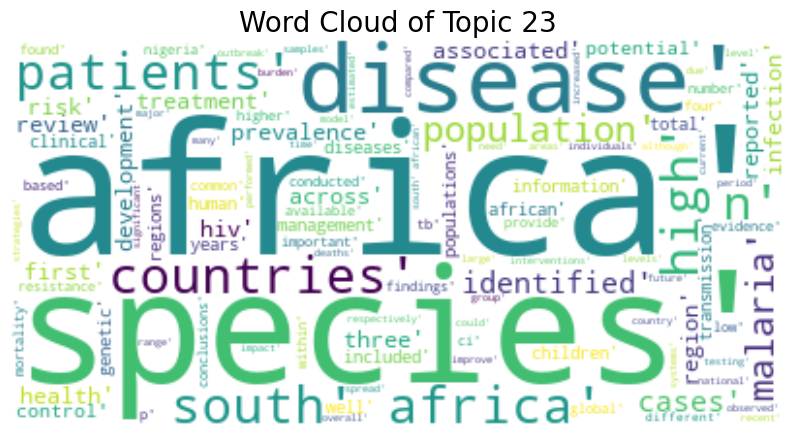

C:\Users\Derek\AppData\Local\Temp\ipykernel_4824\96158943.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  topic_df.dropna(subset=['processed_Abstract'], inplace=True)


Word cloud saved as wordcloud_topic_24.png in the directory: C:\Users\Derek\scopus data anal\DissertationPython Files


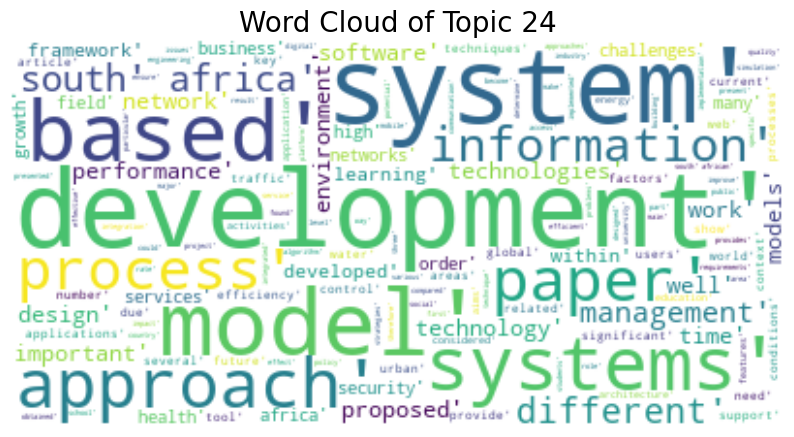

C:\Users\Derek\AppData\Local\Temp\ipykernel_4824\96158943.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  topic_df.dropna(subset=['processed_Abstract'], inplace=True)


Word cloud saved as wordcloud_topic_25.png in the directory: C:\Users\Derek\scopus data anal\DissertationPython Files


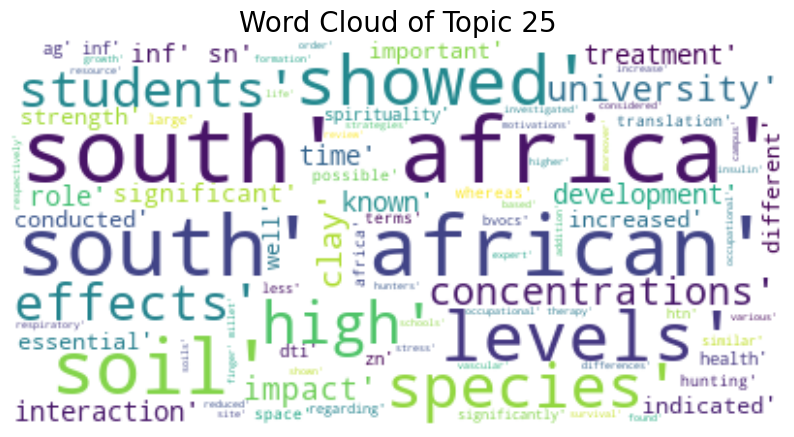

C:\Users\Derek\AppData\Local\Temp\ipykernel_4824\96158943.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  topic_df.dropna(subset=['processed_Abstract'], inplace=True)


Word cloud saved as wordcloud_topic_26.png in the directory: C:\Users\Derek\scopus data anal\DissertationPython Files


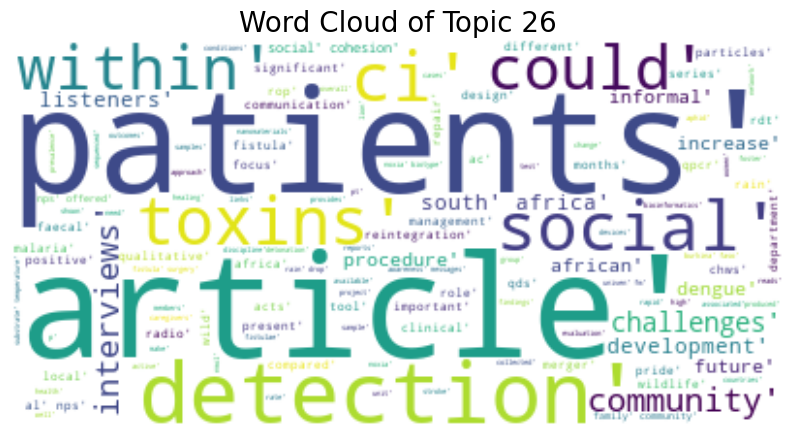

In [13]:
# Filter and generate word cloud for each topic
for topic in range(27):  # Assuming there are 10 topics
    # Filter rows for the current topic
    topic_df = SC_df[SC_df['lda_topics'] == topic]
    
    # Filter out rows where 'processed_Abstract' is 'N/A' after filtering by topic
    topic_df.dropna(subset=['processed_Abstract'], inplace=True)
    
    # Check if there are any rows remaining after filtering
    if not topic_df.empty:
        # Generate word cloud from the 'processed_Abstract' column for the current topic
        plot_wordcloud_from_df(topic_df, 'processed_Abstract', title=f"Word Cloud of Topic {topic}", save_as=f"wordcloud_topic_{topic}.png")
    else:
        print(f"No data available for topic {topic}.")


#                                        # FILTER BY TOPIC

***Creating a CSV file of each topics, save them and count the number of citations. This way the documents that made up each topics can be identified***

***TOPIC ZERO***

In [14]:
# Assuming you want to filter rows where "Topic N°" is equal to a specific value, for example, 3
Topic_0 = SC_df[SC_df['lda_topics'] == 0]
Topic_0 = Topic_0[['Title', 'Abstract', 'Authors', 'Country Affiliation', 'Citations', 'lda_topics']]
# Save the DataFrame to a CSV file
Topic_0.to_csv('Topic 0.csv', index=False)


In [15]:
#Calculate the total number of citations in topic zero

# Convert the column to numeric, ignoring errors
Topic_0['Citations'] = pd.to_numeric(Topic_0['Citations'], errors='coerce')

# Calculate the sum of the 'cited_by_count' column
sum_of_Citations = Topic_0['Citations'].sum()

print(f"Total No of citation in topic 0: {sum_of_Citations}")



Total No of citation in topic 0: 163


***TOPIC ONE***

In [16]:
sec_topic = SC_df[SC_df["lda_topics"] == 1]
sec_topic = sec_topic[['Title', 'Abstract', 'Authors', 'Country Affiliation', 'Citations', 'lda_topics']]
# Save the DataFrame to a CSV file
sec_topic.to_csv('Topic 1.csv', index=False)

In [17]:
# Convert the column to numeric, ignoring errors
sec_topic['Citations'] = pd.to_numeric(sec_topic['Citations'], errors='coerce')

# Calculate the sum of the 'cited_by_count' column
sum_of_Citations = sec_topic['Citations'].sum()

print(f"Total No of Citations in topic 1: {sum_of_Citations}")



Total No of Citations in topic 1: 222


***TOPIC TWO***

In [18]:
third_topic = SC_df[SC_df["lda_topics"] == 2]
third_topic = third_topic[['Title', 'Abstract', 'Authors', 'Country Affiliation', 'Citations', 'lda_topics']]
# Save the DataFrame to a CSV file
third_topic.to_csv('Topic 2.csv', index=False)
third_topic

,Title,Abstract,Authors,Country Affiliation,Citations,lda_topics
0,SMS Marketing: An emergent trend within SMEs,"This chapter seeks to extend current knowledge relating to innovative methods in marketing. The authors consider the significance of SMS marketing amongst Small and Medium Enterprises (SMEs) within South Africa and aim to emphasise the various advantages of SMS marketing to SMEs within emerging economies. They look at how SMS marketing has emerged within the Western world and how it could be just as successful in emerging economies. Different factors are considered such as the background to SMS marketing, what SMS marketing entails, the trends of SMS marketing globally and more specifically within South Africa. The authors then discuss the emergent key themes of SMS marketing relating to its most beneficial characteristics such as cost efficiency, reach, and consumer perceptions. The findings offer significant insight into how SMEs can better understand consumer perceptions about SMS and in turn employ SMS marketing as a source of sustainable competitive advantage.",Takhar A.,South Africa,1,2
2,Computational intelligence in remanufacturing,"In attempts to reduce greenhouse gas emissions, many alternatives to manufacturing have been recommended from a number of international organizations. Although challenges will arise, remanufacturing has the ability to transform ecological and business value. Computational Intelligence in Remanufacturing introduces various computational intelligence techniques that are applied to remanufacturing-related issues, results, and lessons from specific applications while highlighting future development and research. This book is an essential reference for students, researchers, and practitioners in mechanical, industrial, and electrical engineering.",Xing B.,South Africa,7,2
8,Study of hybrid sustainable energy system based on pem fuel cells and photovoltaic-module power generator,"The computer is the greatest innovation of the 20th century. It has changed our lives. It executes tasks with precision. There is no limit with what we can do with software. Computers are seductive. Companies and students cannot work without them. They help students to perform mathematical computations. It is very important that mathematical ideas are expressed in computer programs in order to have theoretical results and to verify them practically. Nowadays, the development of new and non-polluting energy producing and energy-storage systems is a great challenge for scientists. An alternative to the nuclear and fossil fuel power is renewable energy technologies. Due to ever-increasing energy consumption, rising public awareness of environmental protection, and steady progress in power deregulation, alternative (i.e., renewable and fuel cell based) distributed generation systems have attracted increased interest. There is an accelerating world demand for environmentally friendly power. Among the renewable energy sources, the Photovoltaic (PV) energy is the most promising candidate for research and development for large scale users. Fuel cells have been receiving a lot of attention lately due to their potential of becoming a new energy source with a large range of applications. Fuel cells can be incorporated with other components to create high efficiency industrial power plants. Fuel cells permit clean and efficient energy production. The purpose of the work is to optimize the system's operation. The main reason to build described system is to supply stand-alone systems using renewable energy sources. Therefore, the power plant has to produce energy independent of any weather fluctuations. Integrating photovoltaic energy composources with fuel cells, as a storage device replacing the conventional lead-acid batteries, leads to a non-polluting reliable energy source. In this chapter, an energy system comprising different energy sources, namely PV and fuel cells, is proposed. Photovoltaic cells coupled with elect

In [19]:
# Convert the column to numeric, ignoring errors
third_topic['Citations'] = pd.to_numeric(third_topic['Citations'], errors='coerce')

# Calculate the sum of the 'cited_by_count' column
sum_of_Citations = third_topic['Citations'].sum()

print(f"Total No of citations in topic 2: {sum_of_Citations}")



Total No of citations in topic 2: 602


***TOPIC THREE***

In [20]:
fot_topic = SC_df[SC_df["lda_topics"] == 3]
fot_topic = fot_topic[['Title', 'Abstract', 'Authors', 'Country Affiliation', 'Citations', 'lda_topics']]
# Save the DataFrame to a CSV file
fot_topic.to_csv('Topic 3.csv', index=False)
fot_topic

,Title,Abstract,Authors,Country Affiliation,Citations,lda_topics
57,Rediscovering the old from new: Two curious species of Coenosia meigen (Diptera: Muscidae) from South Africa,"Coenosia macrotriseta sp. n. is described from the Western Cape, South Africa, with C. globuliseta Pont being redescribed and new illustrations provided. As judged by external morphological characters, particularly the presence of globular setae, the two species are very closely related. They are, however, very widely separated geographically and differ clearly as regards genital structure.",Muller B.,"South Africa, South Africa",3,3
212,Fermented Poultry Sausages,"Growing interest in poultry and poultry products, especially 100% pure poultry products, has led to the development of a wide range of poultry delicatessen products. These are summarized in this chapter, which places particular emphasis on dry-fermented poultry sausages. The manufacturing process for pure-poultry dry-fermented sausages is described and the two main technological constraints-the sanitary hazards of raw poultry and the poor technological properties of poultry fat-are discussed in relation to the sanitary and sensory qualities of the dry sausages. Promising means of overcoming these constraints are presented.",Arnaud E.,Mauritius,4,3
382,"Zooplankton abundance, species composition and ecology of tropical high-mountain crater Lake Wonchi, Ethiopia","The highlands of Ethiopia represent some of the remnants of undisturbed aquatic ecosystems; they are however highly threatened by significant socio-economic developments and associated anthropogenic impacts. Lake Wonchi is one of the few remaining fairly pristine high-mountain crater lakes in the central highlands and has never been investigated in detail. We present a first study on zooplankton taxa composition, abundance and biomass conducted over more than one year including the underlying environmental drivers. The lake is basic (pH 7.9-8.9), dilute (specific conductivity 185-245 µS cm –1) and oligotrophic with mean trophic status index of 36. The zooplankton community composition showed low species richness comprising a total of fourteen taxa with six cladocerans, one copepod and seven rotifers. Simpson’s index of diversity with values between 0.6 and 0.8 pointed towards a homogenous taxa occurrence within the single sample units. The overall mean (±SD) standing biomass of zooplankton was 62.02±25.76 mg dry mass m –3, which is low compared to other highland and rift valley lakes in Ethiopia. Cyclopoid copepods, in particular Thermocyclops ethiopiensis were the most abundant group and contributed 50% to the total zooplankton abundance followed by cladocerans (38%) and rotifers (12%). Non-metric multi-dimensional scaling resulted in a 3-dimensional model, which revealed similar community composition on successive sampling dates except in December/January and May. Temperature, alkalinity, conductivity and nitrate-N had significant influence on this seasonal pattern. A weak, but significant positive correlation (r=0.482, N=20, P=0.037) between Chlorophyll a and zooplankton biomass mirrors a bottom-up effect of phytoplankton biomass on zooplankton dynamics. The zooplankton of Lake Wonchi displayed some degree of segregation along the epi- and metalimnion during this study, but diel vertical migration was not observed. The results show that fish predation is not the key factor in structuring the vertical distribution of zooplankton in Lake Wonchi.",Degefu F.,Ethiopia,17,3
453,"Genetic diversity analysis in Tunisian perennial ryegrass germplasm as estimated by RAPD, ISSR, and morpho-agronomical markers","Tunisia is rich in diverse forage and pasture species including perennial ryegrass. In order to enhance forage production and improve agronomic performance of this local germplasm, a molecular analysis was undertaken. Random amplified polymorphic DNA (RAPD), inter simple sequence repeats (ISSR) and morpho-agronomical traits markers wer

In [21]:
# Convert the column to numeric, ignoring errors
fot_topic['Citations'] = pd.to_numeric(fot_topic['Citations'], errors='coerce')

# Calculate the sum of the 'cited_by_count' column
sum_of_Citations = fot_topic['Citations'].sum()

print(f"Total No of citations in topic 3: {sum_of_Citations}")

Total No of citations in topic 3: 175


***TOPIC FOUR***

In [22]:
fiv_topic = SC_df[SC_df["lda_topics"] == 4]
fiv_topic = fiv_topic[['Title', 'Abstract', 'Authors', 'Country Affiliation', 'Citations', 'lda_topics']]
# Save the DataFrame to a CSV file
fiv_topic.to_csv('Topic 4.csv', index=False)
fiv_topic

,Title,Abstract,Authors,Country Affiliation,Citations,lda_topics
1,Selection of market entry strategies: Perspectives from the mobile telephony industry in Africa,"The purpose of this chapter is to investigate the selection of market entry strategies in the African mobile telephony industry with a view to developing appropriate business strategies and identifying risk factors. Using the survey methodology, the study focuses on six key enterprises, which account for over 60% of mobile phones in Africa. The empirical evidence suggests that market size in terms of population of the destination country and not psychic distance is the most important market selection criteria for enterprises entering Africa. The dominant entry market strategy for these enterprises is strategic alliances. Focused strategy is uncommon on the continent. More interestingly, and contrary to extant literature, political risk was not considered a market entry barrier. In any case, politically unstable countries tend to bring in higher returns. These findings are critical in informing investors engaged in or with intentions to enter Africa and in enriching international literature. The Stages model and the DMP framework individually are unable to explain the choice of market entry strategy in Africa. The key contributions of this study are both theoretical and practical insights on the process of internationalisation.",Chanakira M.,Zimbabwe,0,4
13,Hydrology and integrated water resource management for sustainable watershed management in Kenya,"Degradation of watersheds and diminishing water resources lead to unsustainable environmental and socio- economic development. The hydrological characteristics are desirable for sustainable water resource exploitation. Hydrological and water resources research were examined in three case watersheds in Kenya leading to the need for integrated water resources management, environmental conservation, and watershed management plans as a result of the major challenges of climate change and variability and uncoordinated watershed resource utilization. Well-managed hydro-meteorological networks at different scales of hydrological systems have been proposed to assess potential for optimal resource use and harmony involving all stakeholders for reduced water stress and future water conflicts. Updates of information and methodologies for watershed management that emphasize collaborative efforts and use of sustainable best practices would require input of various stakeholders including Water Resources Management Authority (WRMA), Basin Authorities, and National Environmental Management Authority (NEMA).",Ondieki C.M.,Kenya,2,4
46,Risk management in cloud computing,"Despite the use of efficient methods of tasks organization that has made optimal planning more possible, the risk of resources unavailability in cloud computing is still present. Taking into consideration the cloud computing bank with a somehow commercial nature, the non availability of resources, such as liquidity risk, remains. This is why we propose, through this paper, the discussion of the possibilities of predicting such a risk by the means so far applied in economy. This work suggests a method used in stock management to predict liquidity risk and proposes a model inspired from fluid mechanic to reduce such a risk. The model is an application of Bernoulli and Torricelli theorems. The resources bank can be considered as a reservoir of liquid; therefore the availability of resources depends necessarily on the liquid flow velocity and the replacement. Torricelli's theorem enables to calculate the velocity of emptying of reservoir. © 2013 IEEE.",Dou El Kefel M.,Algeria,3,4
56,"Local knowledge of plants and their uses among women in the bale mountains, Ethiopia","Women's local ecological knowledge (LEK) is noted by many scholars to be unique and important for local conservation and development planning. Although LEK integration is inherent to ethnobotanical research,

In [23]:
# Convert the column to numeric, ignoring errors
fiv_topic['Citations'] = pd.to_numeric(fiv_topic['Citations'], errors='coerce')

# Calculate the sum of the 'cited_by_count' column
sum_of_Citations = fiv_topic['Citations'].sum()

print(f"Total No of citations in topic 4: {sum_of_Citations}")

Total No of citations in topic 4: 1585


***TOPIC FIVE***

In [24]:
six_topic = SC_df[SC_df["lda_topics"] == 5]
six_topic = six_topic[['Title', 'Abstract', 'Authors', 'Country Affiliation', 'Citations', 'lda_topics']]
# Save the DataFrame to a CSV file
six_topic.to_csv('Topic 5.csv', index=False)
six_topic

,Title,Abstract,Authors,Country Affiliation,Citations,lda_topics
20,Genetic and environmental factors associated with laboratory rearing affect survival and assortative mating but not overall mating success in Anopheles gambiae sensu stricto,"Anopheles gambiae sensu stricto, the main vector of malaria in Africa, is characterized by its vast geographical range and complex population structure. Assortative mating amongst the reproductively isolated cryptic forms that co-occur in many areas poses unique challenges for programs aiming to decrease malaria incidence via the release of sterile or geneticallymodified mosquitoes. Importantly, whether laboratory-rearing affects the ability of An. gambiae individuals of a given cryptic taxa to successfully mate with individuals of their own form in field conditions is still unknown and yet crucial for mosquito-releases. Here, the independent effects of genetic and environmental factors associated with laboratory rearing on male and female survival, mating success and assortative mating were evaluated in the Mopti form of An. gambiae over 2010 and 2011. In semi-field enclosures experiments and despite strong variation between years, the overall survival and mating success of male and female progeny from a laboratory strain was not found to be significantly lower than those of the progeny of field females from the same population. Adult progeny from field-caught females reared at the larval stage in the laboratory and from laboratory females reared outdoors exhibited a significant decrease in survival but not in mating success. Importantly, laboratory individuals reared as larvae indoors were unable to mate assortatively as adults, whilst field progeny reared either outdoors or in the laboratory, as well as laboratory progeny reared outdoors all mated significantly assortatively. These results highlight the importance of genetic and environment interactions for the development of An. gambiae's full mating behavioral repertoire and the challenges this creates for mosquito rearing and release-based control strategies. © 2013 Paton et al.",Paton D.,Mali,14,5
33,Sigmoid utility function formulation for handoff reducing Access model in cognitive radio,This paper investigates the issue of determining an appropriate utility function to model the Secondary User (SU) preference toward spectrum holes on the basis of their duration. A Sigmoid shaped utility function is proposed and a proper tuning is discussed to improve the representation of SU preference and to involve the radio quality on the access decision process. The performance and the suitability of the proposed utility function is investigated within an access model whose purpose is to reduce handoff process related to PU activity. © 2013 IEEE.,Dahi S.,Tunisia,5,5
44,"Foundation studies, analyses and design in a highly fractured aquaferous zone","Foundation studies, analyses and design work for a proposed office development in the central area of the Federal capital city (FCC) of Nigeria is presented herein. Extensive field works, laboratory tests and analyses as well as analyses of the deduced data were involved in the work. Specifically, a total of three (3 Nos.) rotary drillings with rock coring was carried out in addition to twenty (20 Nos.) mechanised percussion drilling with standard penetration test (SPT). The former were done up to 15- 19.5m while the latter were carried out to maximum depths of between 8.15 - 9.65m. The materials proved from both sets of borings include silty sand, sandy silt, laterite, lateritic clay and concretionary laterite. Weathered and fresh basement rock were recovered between 9 - 19.5m. Geophysical survey results show extensive fractures which are water bearing. Consequently, water table was high (between 0.9 - 2.1m) compared to the proposed foundation level of 2.1m. In order to take care of both the bearing pressure (48 - 400 kN/m2, using a factor of safety of 2.5) Raft foundation with ground beams were p

In [25]:
# Convert the column to numeric, ignoring errors
six_topic['Citations'] = pd.to_numeric(six_topic['Citations'], errors='coerce')

# Calculate the sum of the 'cited_by_count' column
sum_of_Citations = six_topic['Citations'].sum()

print(f"Total No of citations in topic 5: {sum_of_Citations}")

Total No of citations in topic 5: 398


***TOPIC SIX***

In [26]:
sev_topic = SC_df[SC_df["lda_topics"] == 6]
sev_topic = sev_topic[['Title', 'Abstract', 'Authors', 'Country Affiliation', 'Citations', 'lda_topics']]
# Save the DataFrame to a CSV file
sev_topic.to_csv('Topic 6.csv', index=False)
sev_topic

,Title,Abstract,Authors,Country Affiliation,Citations,lda_topics
18,Low levels of peripheral CD161++CD8+ Mucosal Associated Invariant T (MAIT) cells are found in HIV and HIV/TB co-infection,"Background: High expression of CD161 on CD8+ T cells is associated with a population of cells thought to play a role in mucosal immunity. We wished to investigate this subset in an HIV and Mycobacterium tuberculosis (MTB) endemic African setting. Methods: A flow cytometric approach was used to assess the frequency and phenotype of CD161++CD8+ T cells. 80 individuals were recruited for cross-sectional analysis: controls (n = 18), latent MTB infection (LTBI) only (n = 16), pulmonary tuberculosis (TB) only (n = 8), HIV only (n = 13), HIV and LTBI co-infection (n = 15) and HIV and TB co-infection (n = 10). The impact of acute HIV infection was assessed in 5 individuals recruited within 3 weeks of infection. The frequency of CD161++CD8+ T cells was assessed prior to and during antiretroviral therapy (ART) in 14 HIV-positive patients. Results: CD161++CD8+ T cells expressed high levels of the HIV co-receptor CCR5, the tissue-homing marker CCR6, and the Mucosal-Associated Invariant T (MAIT) cell TCR Vα7.2. Acute and chronic HIV were associated with lower frequencies of CD161++CD8+ T cells, which did not correlate with CD4 count or HIV viral load. ART was not associated with an increase in CD161++CD8+ T cell frequency. There was a trend towards lower levels of CD161++CD8+ T cells in HIV-negative individuals with active and latent TB. In those co-infected with HIV and TB, CD161++CD8+ T cells were found at low levels similar to those seen in HIV mono-infection. Conclusions: The frequencies and phenotype of CD161++CD8+ T cells in this South African cohort are comparable to those published in European and US cohorts. Low-levels of this population were associated with acute and chronic HIV infection. Lower levels of the tissue-trophic CD161++CD8+ T cell population may contribute to weakened mucosal immune defense, making HIV-infected subjects more susceptible to pulmonary and gastrointestinal infections and detrimentally impacting on host defense against TB.",Wong E.B.,"South Africa, South Africa",75,6
51,Role of cyclooxygenase-2 enzyme in human transitional cell carcinoma of the urinary bladder,"Cyclooxygenase (COX) is considered a key enzyme in the synthesis of prostaglandins from arachidonic acid. The enzyme is believed to be involved in the inflammation, proliferation and differentiation of cells. The generated form of COX, COX-2, is increased in colonic carcinoma. To evaluate the importance of COX-2 in tumor development in the urinary bladder, the expression of COX-2 in transitional cell carcinoma of the bladder was examined to determine the usage of selective COX-2 inhibitor treatment targeting COX-2. Sixty patients with pathologically diagnosed invasive transitional cell carcinoma of the urinary bladder (pT2-pT4) were evaluated. Immunohistochemical staining was used to evaluate COX-2 expression and cases with staining of 10% of tumor cells were defined as positive. The results indicated that in 5 patients, 0 % of the primary tumors stained for COX-2, while 1-5 % was stained in 20 patients, 6-10% in 7 patients and 10% in 28 patients (28/60, 46.7%). In terms of grade, 4 patients with grade 2 (4/6, 66.6%) and 24 patients with grade 3 (24/54, 46.7%) were COX-2 positive. When categorized by stage, 16 patients with PT2 (16/33, 48.5%), 9 patients with pT3 (9/20, 45%) and 3 patients with pT4 (3/7, 42.9%) were positive. Lymph node metastasis was observed in 15 patients; 4 of them, with pN2, were COX-2-positive.Those with COX-2-positive metastatic lymph nodes had grade 3 primary tumors, which were also COX-2- positive. In addition, COX-2-negative metastatic lymph node patients also had negative primary tumors. The results of this study suggested that 46.7% of patients with invasive bladder cancer may show benefit from treatment with selective COX-2- inhibi

In [27]:
# Convert the column to numeric, ignoring errors
sev_topic['Citations'] = pd.to_numeric(sev_topic['Citations'], errors='coerce')

# Calculate the sum of the 'cited_by_count' column
sum_of_Citations = sev_topic['Citations'].sum()

print(f"Total No of citations in topic 6: {sum_of_Citations}")

Total No of citations in topic 6: 7371


***TOPIC SEVEN***

In [28]:
eig_topic = SC_df[SC_df["lda_topics"] == 7]
eig_topic = eig_topic[['Title', 'Abstract', 'Authors', 'Country Affiliation', 'Citations', 'lda_topics']]
# Save the DataFrame to a CSV file
eig_topic.to_csv('Topic 7.csv', index=False)
eig_topic

,Title,Abstract,Authors,Country Affiliation,Citations,lda_topics
116,Stuck in stabilisation? South Africa's post-apartheid macro-economic policy between ideological conversion and technocratic capture,"This article explores post-apartheid South Africa's commitment to macro-economic orthodoxy. Its key argument is that South Africa offers an exemplary case of neoliberal deepening which has entailed three interconnected processes: ideological conversion, a stated focus on poverty and development covering a deep commitment to orthodox macro policies, entailing institutions and a set of practices, and a far-reaching state restructuring involving the emergence and consolidation of a hegemonic treasury. Drawing on an analysis of grey literature, policy documents and a series of interviews with policy-makers, the article first discusses neoliberalism in South Africa, focusing on the 'conversion' of key ANC leaders to neoclassical economic orthodoxy. It then turns to the central, yet under-researched, instrument of neoliberal deepening: the emergence and consolidation of a dominant national treasury with the ability to shape policy-making across all areas of state intervention. The article closes on a call to envisage concurrently ideological conversion and state formation to understand the dynamics of neoliberalism, and its paradoxical resilience in the South Africa case. © 2013 ROAPE Publications Ltd.",Segatti A.,South Africa,16,7
126,Evaluation of the hydropower potential of Otamiri river for electric power generation,"This research presents the estimation of the hydropower potential of River Otamiri through the hydrological analysis of the elements of climate as it affects its catchment area (section passing through the Federal University of Technology Owerri). The study involves the estimation of maximum design floods for the watershed using the Gumbels Probability Distribution Method for various return periods (Tr) with the development of unit hydrograph, storm hydrograph, runoffhydrograph and flood duration curve for the catchment area of the river. In addition watershed parameters like peak flow (Qp), lag time (Tl), time of concentration (Tc) and rainfall intensity (Ic) were determined using the soil conservation service method and other empirical formulas. In order to determine the available flow for power generation, the stage/head of the river was estimated from records provided by the River Basin Development Authority (R.B.D.A) and flow duration analyses were carried out. The analysis revealed that for time flows of 50, 75 and 100% the following energy values were obtained 34.5 MW, 11.3 MW and 1.5 MW, respectively. © Maxwell Scientific Organization, 2013.",Okorafor O.O.,Nigeria,4,7
156,Vascular endothelial growth factor in children with thalassemia major,"Background: The β-Thalassemia syndromes are the most common hereditary chronic hemolytic anemia due to impaired globin chain synthesis. Vascular endothelial growth factor (VEGF) plays several roles in angiogenesis which is a crucial process in the pathogenesis of several inflammatory, autoimmune and malignant diseases. Endothelial damage and inflammation make a significant contribution to the pathophysiology of β-thalassemia. Purpose: The aim of the study was to assess serum VEGF level in children with beta-thalassemia major as a marker of angiogenesis. Methods: A total of 50 children entered the study, 40 patients with thalassemia major and 10 healthy controls. We used enzyme-linked immunosorbent assay for quantitative evaluation of VEGF. Results: VEGF level was significantly higher in patients with β-thalassemia major than healthy controls (p=0.001). VEGF level was also higher in splenectomised thalassemic patients than non splenectomised ones (p=0.001). There were a positive correlation between VEGF and chelation starting age (p=0.008), and a negative correlation between VEGF and frequency of blood transfusion (p=0.002). Conclusion: Thalassemia patients, especially sple

In [29]:
# Convert the column to numeric, ignoring errors
eig_topic['Citations'] = pd.to_numeric(eig_topic['Citations'], errors='coerce')

# Calculate the sum of the 'cited_by_count' column
sum_of_Citations = eig_topic['Citations'].sum()

print(f"Total No of citations in topic 7: {sum_of_Citations}")

Total No of citations in topic 7: 579


***TOPIC EIGHT***

In [30]:
nin_topic = SC_df[SC_df["lda_topics"] == 8]
nin_topic = nin_topic[['Title', 'Abstract', 'Authors', 'Country Affiliation', 'Citations', 'lda_topics']]
# Save the DataFrame to a CSV file
nin_topic.to_csv('Topic 8.csv', index=False)
nin_topic

,Title,Abstract,Authors,Country Affiliation,Citations,lda_topics
35,"Altos de Tinogasta, Argentina","This case challenges students to develop alternatives for (within the next 12 months) very substantially increasing the revenues of the Altos de Tinogasta ""productive real estate"" company in Argentina. The case is based on data collected by one of the authors in Argentina. The case is appropriate for senior-level undergraduates as well as students in MBA and Executive Development programs. It is designed to be taught in a one hour and a half class session, and is likely to require at least a couple hours of preparation by students. Mr. Gabriel Clusellas is President of Altos de Tinogasta-La Aguadita S.A., a farming/real estate company located on 3000 hectares in the town of Tinogasta, Province of Catamarca, in Argentina. The business model Altos de Tinogasta (hence, AT) is using, and the results the company has achieved so far, are as indicated below: 1. The 3000 hectares are being planted in two crops: olives and grapes. The first harvests will be in 2013. 2. The hectares being planted in olives have been divided up into 216 parcels of 10,000 square meters each; these parcels are being offered to investors at a price of $27,000 per parcel. The hectares being planted in grapes have been divided up into 208 parcels of 2,500 square meters each; these parcels are being offered to investors at a price of $15,000 per parcel. 3. Of the 104 parcels planted in grapes so far, 81 (that is, 78%) have been sold. Of the 108 parcels planted in olives so far, 40 (that is, 37%) have been sold. However, the trend in sales is not reassuring: After a very strong performance in 2010 (a total of 71 parcels were sold that year), only 22 parcels were sold in 2011 while in the first half of 2012, only 8 parcels were sold. To continue developing its infrastructure and to continue planting additional parcels with olives or grapes, AT needs to substantially increase its revenues. 4.4. The objective Mr. Clusellas has set for the company is to generate revenues of at least $2,000,000 within the next 12 months; this would be a very substantial increase in the total revenue of approximately $500,000 generated by sales of plots in 2011. 5. Mr. Clusellas has invited Professor Carlos Aimar to develop (within 30 days) a set of alternatives for achieving the above objective, that is, that over the next 12 months, AT should generate at least $2,000,000 of revenue. Additional data and information in the case include: 1. Regarding Argentina: Historical overview, a sample of recent demographic statistics from the World Bank, (and for benchmarking purposes, comparable statistics for the United States), plus information on the economy of Argentina. 2. Regarding the company: Business model, current marketing strategy, current performance, and numerous factors impacting that performance. 3. Additional information: Information on the activities, interests, and opinions of members of the market AT has targeted, information about competing products (both domestic and international), and information about the real estate industry in Argentina. © 2013 by Jordan Whitney Enterprises, Inc, Arden NC, USA.",Smith D.K.,Nigeria,0,8
179,Microcalorimetric evaluation of soil microbiological properties under plant residues and dogmatic water gradients in Red soil,"A study of 6 months duration was carried out to investigate the effect of water regimes and organic amendments on the soil microbial biomass and microbial population under Red soil collected from Hunan Providence, China. The soil microbial biomass and population were measured with traditional methods and results obtained by conventional methods, corroborated with microcalorimetry. The incorporation of rice (Oryza sativa L.) straw (RS) and green manure (GM), especially at high rates, enhanced the soil microbial activities. We observed that the use of GM exhibited more significant stimulating effects on microbial activities th

In [31]:
# Convert the column to numeric, ignoring errors
nin_topic['Citations'] = pd.to_numeric(nin_topic['Citations'], errors='coerce')

# Calculate the sum of the 'cited_by_count' column
sum_of_Citations = nin_topic['Citations'].sum()

print(f"Total No of citations in topic 8: {sum_of_Citations}")

Total No of citations in topic 8: 336


***TOPIC NINE***

In [32]:
ten_topic = SC_df[SC_df["lda_topics"] == 9]
ten_topic = ten_topic[['Title', 'Abstract', 'Authors', 'Country Affiliation', 'Citations', 'lda_topics']]
# Save the DataFrame to a CSV file
ten_topic.to_csv('Topic 9.csv', index=False)
ten_topic

,Title,Abstract,Authors,Country Affiliation,Citations,lda_topics
31,Electrical circuit analysis of CO poisoning in high temperature PEM fuel cells for rapid fault diagnostics,High Temperature PEM fuel cells are able to withstand a substantial amount of CO poisoning while still maintaining stable output. High concentrations of CO will however degrade performance and can lead to instability. This paper presents a detailed study on the impact of CO poisoning on the performance of High Temperature PEM fuel cells. A dedicated test setup was constructed to perform both steady state and dynamic analysis on the fuel cell under a wide range of operating conditions and variations in CO content. The drop in performance captured in the polarization curves is modeled using a simple circuit model with a dedicated fault element. The captured impedance spectra from the electrochemical impedance spectroscopy (EIS) tests provide insight to the changes in the electrochemical circuit parameters during CO poisoning that can be used to track the fuel cell state of health. The results from this study will allow for the development of a rapid diagnostic control system that can be implemented in the power conditioning unit of the fuel cell. © 2013 IEEE.,De Beer C.,South Africa,6,9
94,Organisational impact of implementing IEC 61850 standard for communication networks and systems in substations,"The lack of international standards for communication within a substation led to the development of proprietary protocols by utilities and vendors. The impact on utilities was complex and required expensive solutions, and limitations in multiple vendor solutions for substations infrastructure. Towards the end of the 20th century there was a compelling requirement in the power industry to standardise protocols for substation automation systems that would enable multiple vendor substation solutions. The requirement prompted the development of the IEC 61850 standard in 1997, a standard for Communication Networks and Systems in Substation. A case study was conducted at Eskom to establish the relationships between the substation function consolidation (enabled by technological advancement) and IEC 61850 standard, as well as organisational structure and the skills required by the power utilities. The case study findings highlighted that the skills and competency requirements were not properly defined, measured or monitored, nor was an alignment to the existing organisational structures defined. Based on the findings the authors propose a framework model to map the requirements of IEC 61850 with the capabilities of the organisation, and formulate a potential solution for the implementation of the IEC 61850 standard. © 2013 PICMET.",Madiba R.P.,South Africa,1,9
181,"Variability in the egg production rates of the calanoid copepod, Pseudodiaptomus hessei in a South African estuary in relation to environmental factors","The importance of physical parameters (temperature and salinity) and seston composition (chlorophyll a, protein, carbohydrate and lipid concentration as well as fatty acid composition) in controlling the in situ egg productions rate (EPR) of the calanoid copepod, Pseudodiaptomus hessei, was investigated monthly in a permanently open South African estuary over a one year period. The EPR of P.hessei ranged from 3.00 to 37.23 eggsF-1d-1 and were amongst the highest rates published for egg-carrying copepods. EPR varied significantly between months while hatching success was constant and high throughout the study period (91% on average). A stepwise multiple linear regression selected temperature - Chl a 2-20μm size fraction and temperature - 16:1(n-7) as the best descriptors of EPR (R2=0.86) and nauplii production (R2=0.92), respectively. The maximum values of EPR were recorded in September and December, following freshwater inflow into the estuary. September had an extremely high level of Chl a while December showed only an average level. We suggest that the EP

In [33]:
# Convert the column to numeric, ignoring errors
ten_topic['Citations'] = pd.to_numeric(ten_topic['Citations'], errors='coerce')

# Calculate the sum of the 'cited_by_count' column
sum_of_Citations = ten_topic['Citations'].sum()

print(f"Total No of citations in topic 9: {sum_of_Citations}")

Total No of citations in topic 9: 159


***Lets see the number of citations for each topic***

In [34]:
print(f"Total No of citations in topic 0: {Topic_0['Citations'].sum()}"),
print(f"Total No of citations in topic 1: {sec_topic['Citations'].sum()}"),
print(f"Total No of citations in topic 2: {third_topic['Citations'].sum()}"),
print(f"Total No of citations in topic 3: {fot_topic['Citations'].sum()}"),
print(f"Total No of citations in topic 4: {fiv_topic['Citations'].sum()}"),
print(f"Total No of citations in topic 5: {six_topic['Citations'].sum()}"),
print(f"Total No of citations in topic 6: {sev_topic['Citations'].sum()}"),
print(f"Total No of citations in topic 7: {eig_topic['Citations'].sum()}"),
print(f"Total No of citations in topic 8: {nin_topic['Citations'].sum()}"),
print(f"Total No of citations in topic 9: {ten_topic['Citations'].sum()}")

Total No of citations in topic 0: 163
Total No of citations in topic 1: 222
Total No of citations in topic 2: 602
Total No of citations in topic 3: 175
Total No of citations in topic 4: 1585
Total No of citations in topic 5: 398
Total No of citations in topic 6: 7371
Total No of citations in topic 7: 579
Total No of citations in topic 8: 336
Total No of citations in topic 9: 159


# LDA VISUALIZATION

In [35]:
import pyLDAvis.gensim
from gensim.models import LdaModel
from gensim.corpora import Dictionary


# Convert Gensim LdaModel to a format pyLDAvis understands
lda_data = pyLDAvis.gensim.prepare(lda_model, corpus, dictionary)

# Save the visualization to an HTML file
pyLDAvis.save_html(lda_data, 'lda_visualization.html')

# Display the visualization (optional)
pyLDAvis.display(lda_data)


In [36]:
SC_df.head(2)

,Title,Abstract,Authors,Citations,Year,Country Affiliation,processed_Abstract,lda_topics
0,SMS Marketing: An emergent trend within SMEs,"This chapter seeks to extend current knowledge relating to innovative methods in marketing. The authors consider the significance of SMS marketing amongst Small and Medium Enterprises (SMEs) within South Africa and aim to emphasise the various advantages of SMS marketing to SMEs within emerging economies. They look at how SMS marketing has emerged within the Western world and how it could be just as successful in emerging economies. Different factors are considered such as the background to SMS marketing, what SMS marketing entails, the trends of SMS marketing globally and more specifically within South Africa. The authors then discuss the emergent key themes of SMS marketing relating to its most beneficial characteristics such as cost efficiency, reach, and consumer perceptions. The findings offer significant insight into how SMEs can better understand consumer perceptions about SMS and in turn employ SMS marketing as a source of sustainable competitive advantage.",Takhar A.,1,2013,South Africa,"['chapter', 'seeks', 'extend', 'current', 'knowledge', 'relating', 'innovative', 'marketing', 'authors', 'consider', 'significance', 'sms', 'marketing', 'amongst', 'small', 'medium', 'enterprises', 'smes', 'within', 'south', 'africa', 'emphasise', 'various', 'advantages', 'sms', 'marketing', 'smes', 'within', 'emerging', 'economies', 'look', 'sms', 'marketing', 'emerged', 'within', 'western', 'world', 'could', 'successful', 'emerging', 'economies', 'different', 'factors', 'considered', 'sms', 'marketing', 'sms', 'marketing', 'entails', 'trends', 'sms', 'marketing', 'globally', 'specifically', 'within', 'south', 'africa', 'authors', 'discuss', 'emergent', 'key', 'themes', 'sms', 'marketing', 'relating', 'beneficial', 'characteristics', 'cost', 'efficiency', 'reach', 'consumer', 'perceptions', 'findings', 'offer', 'significant', 'insight', 'smes', 'better', 'understand', 'consumer', 'perceptions', 'sms', 'turn', 'employ', 'sms', 'marketing', 'source', 'sustainable', 'competitive', 'advantage']",2
1,Selection of market entry strategies: Perspectives from the mobile telephony industry in Africa,"The purpose of this chapter is to investigate the selection of market entry strategies in the African mobile telephony industry with a view to developing appropriate business strategies and identifying risk factors. Using the survey methodology, the study focuses on six key enterprises, which account for over 60% of mobile phones in Africa. The empirical evidence suggests that market size in terms of population of the destination country and not psychic distance is the most important market selection criteria for enterprises entering Africa. The dominant entry market strategy for these enterprises is strategic alliances. Focused strategy is uncommon on the continent. More interestingly, and contrary to extant literature, political risk was not considered a market entry barrier. In any case, politically unstable countries tend to bring in higher returns. These findings are critical in informing investors engaged in or with intentions to enter Africa and in enriching international literature. The Stages model and the DMP framework individually are unable to explain the choice of market entry strategy in Africa. The key contributions of this study are both theoretical and practical insights on the process of internationalisation.",Chanakira M.,0,2013,Zimbabwe,"['purpose', 'chapter', 'investigate', 'selection', 'market', 'entry', 'strategies', 'african', 'mobile', 'telephony', 'industry', 'view', 'developing', 'appropriate', 'business', 'strategies', 'identifying', 'risk', 'factors', 'survey', 'focuses', 'six', 'key', 'enterprises', 'account', 'mobile', 'phones', 'africa', 'empirical', 'evidence', 'suggests', 'market', 'size', 'terms', 'population', 'destination', 'country', 'psychic', 'distance', 'important', 'marke

***Count the number of articles that made up each topic***

In [37]:
# Create an empty dictionary to store tokens for each topic
topic_tokens = {}
data_counts_per_topic = {}  # Dictionary to store the count of data for each topic

# Filter and collect tokens for each topic
for topic in range(27):  # Assuming there are 27 topics
    # Filter rows for the current topic and make a copy to avoid SettingWithCopyWarning
    topic_df = SC_df[SC_df['lda_topics'] == topic].copy()
    
    # Filter out rows where 'processed_Abstract' is 'N/A' after filtering by topic
    topic_df.dropna(subset=['processed_Abstract'], inplace=True)  # Adjust column name here
    
    # Print the number of rows for the current topic
    print(f"Number of rows for Topic {topic}: {len(topic_df)}")
    
    # Check if there are any rows remaining after filtering
    if not topic_df.empty:
        # Collect tokens for the current topic
        tokens = [token for abstract_tokens in topic_df['processed_Abstract'] for token in abstract_tokens]
        
        # Store tokens for the current topic in the dictionary
        topic_tokens[topic] = tokens
        
        # Store the count of data for the current topic
        data_counts_per_topic[topic] = len(topic_df)
    else:
        print(f"No data available for topic {topic}.")

# Now you can use data_counts_per_topic to get the count of data for each topic.



Number of rows for Topic 0: 14
Number of rows for Topic 1: 36
Number of rows for Topic 2: 46
Number of rows for Topic 3: 28
Number of rows for Topic 4: 171
Number of rows for Topic 5: 27
Number of rows for Topic 6: 234
Number of rows for Topic 7: 44
Number of rows for Topic 8: 23
Number of rows for Topic 9: 29
Number of rows for Topic 10: 33
Number of rows for Topic 11: 41
Number of rows for Topic 12: 40
Number of rows for Topic 13: 26
Number of rows for Topic 14: 37
Number of rows for Topic 15: 21
Number of rows for Topic 16: 98
Number of rows for Topic 17: 37
Number of rows for Topic 18: 154
Number of rows for Topic 19: 41
Number of rows for Topic 20: 43
Number of rows for Topic 21: 263
Number of rows for Topic 22: 24
Number of rows for Topic 23: 298
Number of rows for Topic 24: 283
Number of rows for Topic 25: 26
Number of rows for Topic 26: 23


***Repeat same for citations to know the number of citations each topic attracted***

In [38]:
# Create an empty dictionary to store total citations for each topic
topic_citations = {}

# Aggregate total citations for each topic
for topic in range(27):  # Assuming there are 27 topics
    # Filter rows for the current topic and make a copy to avoid SettingWithCopyWarning
    topic_df = SC_df[SC_df['lda_topics'] == topic].copy()
    
    # Compute total citations for the current topic
    total_citations = topic_df['Citations'].sum()  # Assuming 'Citations' is the column containing citation counts
    
    # Store total citations for the current topic in the dictionary
    topic_citations[topic] = total_citations

# Print total citations for each topic
for topic, citations in topic_citations.items():
    print(f"Total citations for Topic {topic}: {citations}")


Total citations for Topic 0: 163
Total citations for Topic 1: 222
Total citations for Topic 2: 602
Total citations for Topic 3: 175
Total citations for Topic 4: 1585
Total citations for Topic 5: 398
Total citations for Topic 6: 7371
Total citations for Topic 7: 579
Total citations for Topic 8: 336
Total citations for Topic 9: 159
Total citations for Topic 10: 940
Total citations for Topic 11: 462
Total citations for Topic 12: 920
Total citations for Topic 13: 406
Total citations for Topic 14: 302
Total citations for Topic 15: 152
Total citations for Topic 16: 545
Total citations for Topic 17: 459
Total citations for Topic 18: 2356
Total citations for Topic 19: 927
Total citations for Topic 20: 362
Total citations for Topic 21: 2925
Total citations for Topic 22: 197
Total citations for Topic 23: 6340
Total citations for Topic 24: 2729
Total citations for Topic 25: 270
Total citations for Topic 26: 163


***A bar plot of citations per topic***

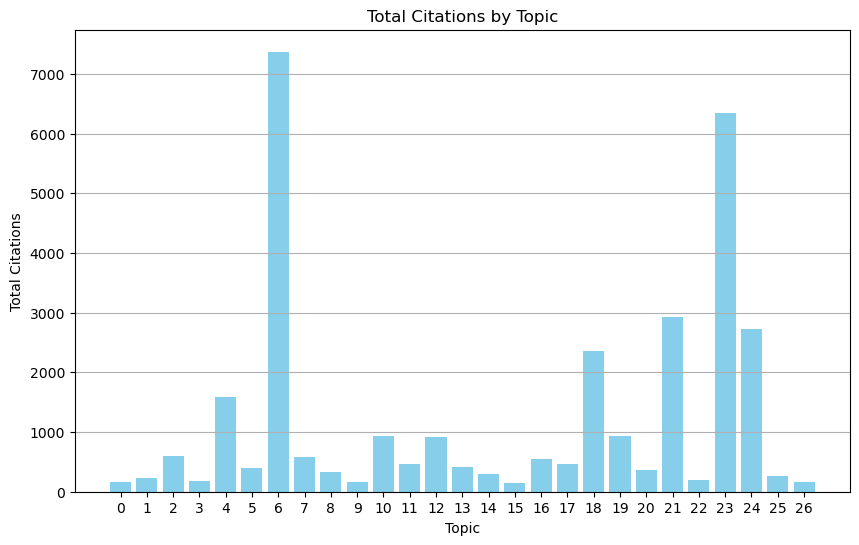

In [39]:
import matplotlib.pyplot as plt

# Convert topic_citations dictionary to lists for plotting
topics = list(topic_citations.keys())
citations = list(topic_citations.values())

# Plot bar chart
plt.figure(figsize=(10, 6))
plt.bar(topics, citations, color='skyblue')
plt.xlabel('Topic')
plt.ylabel('Total Citations')
plt.title('Total Citations by Topic')
plt.xticks(topics)
plt.grid(axis='y')
plt.show()


***Lets create a table of number of data and citations per topic for easy comparism***

In [40]:
import pandas as pd

# Create lists to store topic number, number of data per topic, and number of citations
topic_numbers = []
data_counts = []  # Replace this with data_counts_per_topic from the previous code
citation_counts = []

# Iterate through the topic_tokens dictionary to collect data
for topic, tokens in topic_tokens.items():
    # Append topic number
    topic_numbers.append(topic)
    
    # Append number of data per topic
    # Replace len(tokens) with data_counts_per_topic[topic]
    data_counts.append(data_counts_per_topic[topic])
    
    # Calculate number of citations for the current topic
    citations_for_topic = SC_df[SC_df['lda_topics'] == topic]['Citations'].sum()  # Adjust column name if needed
    
    # Append number of citations
    citation_counts.append(citations_for_topic)

# Create DataFrame
topic_df = pd.DataFrame({
    'Topic Number': topic_numbers,
    'Number of Data': data_counts,
    'Number of Citations': citation_counts
})

# Add a last row with the sum of each column
sum_row = topic_df.sum(numeric_only=True)
sum_row['Topic Number'] = 'Total'
topic_df = pd.concat([topic_df, pd.DataFrame(sum_row).transpose()], ignore_index=True)

# Display DataFrame
topic_df


C:\Users\Derek\AppData\Local\Temp\ipykernel_4824\354721931.py:32: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value 'Total' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  sum_row['Topic Number'] = 'Total'


,Topic Number,Number of Data,Number of Citations
0,0,14,163
1,1,36,222
2,2,46,602
3,3,28,175
4,4,171,1585
5,5,27,398
6,6,234,7371
7,7,44,579
8,8,23,336
9,9,29,159


***visualise them in a bar plot***

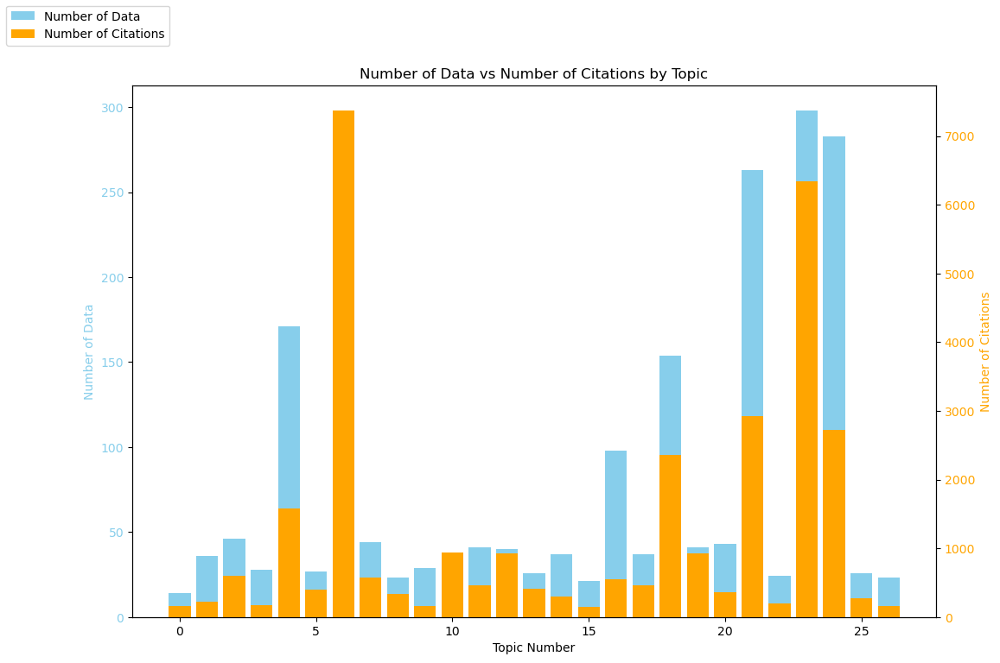

In [41]:

import matplotlib.pyplot as plt

# Exclude the 'Total' row for plotting
plot_data = topic_df[topic_df['Topic Number'] != 'Total']

# Sort the data by 'Number of Citations'
plot_data = plot_data.sort_values(by='Number of Citations')

# Create figure and axis objects
fig, ax1 = plt.subplots(figsize=(12, 8))

# Plot Number of Data
ax1.bar(plot_data['Topic Number'], plot_data['Number of Data'], color='skyblue', label='Number of Data')

# Set the label and tick parameters for the first y-axis
ax1.set_xlabel('Topic Number')
ax1.set_ylabel('Number of Data', color='skyblue')
ax1.tick_params(axis='y', labelcolor='skyblue')

# Create a secondary y-axis for Number of Citations
ax2 = ax1.twinx()
ax2.bar(plot_data['Topic Number'], plot_data['Number of Citations'], color='orange', label='Number of Citations')

# Set the label and tick parameters for the secondary y-axis
ax2.set_ylabel('Number of Citations', color='orange')
ax2.tick_params(axis='y', labelcolor='orange')

# Set the title
plt.title('Number of Data vs Number of Citations by Topic')

# Add legend
fig.legend(loc='upper left')

# Rotate x-axis labels for better readability
plt.xticks(rotation=45)

# Save the plot
plt.savefig('Data_vs_Citations_plot.png')

plt.show()


In [67]:
# Sort the DataFrame by the 'Number of Data' column in descending order to exclude the last row
sorted_topic_df = topic_df[:-1].sort_values(by='Number of Citations', ascending=False)

# Display the sorted DataFrame
sorted_topic_df


,Topic Number,Number of Data,Number of Citations
6,6,234,7371
23,23,298,6340
21,21,263,2925
24,24,283,2729
18,18,154,2356
4,4,171,1585
10,10,33,940
19,19,41,927
12,12,40,920
2,2,46,602


In [50]:
topic6 = SC_df[SC_df["lda_topics"] == 6]
topic6 = topic6[['Title', 'Abstract', 'Authors', 'Country Affiliation', 'Citations', 'lda_topics']]
# Save the DataFrame to a CSV file
topic6.to_csv('Topic 6.csv', index=False)

# Sort the DataFrame by 'Total Count' column
topic6sorted = topic6.sort_values(by='Citations', ascending=False)

# Display the sorted DataFrame
topic6sorted.head(8)



,Title,Abstract,Authors,Country Affiliation,Citations,lda_topics
1711,"Worldwide trends in body-mass index, underweight, overweight, and obesity from 1975 to 2016: a pooled analysis of 2416 population-based measurement studies in 128·9 million children, adolescents, and adults","Background Underweight, overweight, and obesity in childhood and adolescence are associated with adverse health consequences throughout the life-course. Our aim was to estimate worldwide trends in mean body-mass index (BMI) and a comprehensive set of BMI categories that cover underweight to obesity in children and adolescents, and to compare trends with those of adults. Methods We pooled 2416 population-based studies with measurements of height and weight on 128·9 million participants aged 5 years and older, including 31·5 million aged 5–19 years. We used a Bayesian hierarchical model to estimate trends from 1975 to 2016 in 200 countries for mean BMI and for prevalence of BMI in the following categories for children and adolescents aged 5–19 years: more than 2 SD below the median of the WHO growth reference for children and adolescents (referred to as moderate and severe underweight hereafter), 2 SD to more than 1 SD below the median (mild underweight), 1 SD below the median to 1 SD above the median (healthy weight), more than 1 SD to 2 SD above the median (overweight but not obese), and more than 2 SD above the median (obesity). Findings Regional change in age-standardised mean BMI in girls from 1975 to 2016 ranged from virtually no change (−0·01 kg/m2 per decade; 95% credible interval −0·42 to 0·39, posterior probability [PP] of the observed decrease being a true decrease=0·5098) in eastern Europe to an increase of 1·00 kg/m2 per decade (0·69–1·35, PP>0·9999) in central Latin America and an increase of 0·95 kg/m2 per decade (0·64–1·25, PP>0·9999) in Polynesia and Micronesia. The range for boys was from a non-significant increase of 0·09 kg/m2 per decade (−0·33 to 0·49, PP=0·6926) in eastern Europe to an increase of 0·77 kg/m2 per decade (0·50–1·06, PP>0·9999) in Polynesia and Micronesia. Trends in mean BMI have recently flattened in northwestern Europe and the high-income English-speaking and Asia-Pacific regions for both sexes, southwestern Europe for boys, and central and Andean Latin America for girls. By contrast, the rise in BMI has accelerated in east and south Asia for both sexes, and southeast Asia for boys. Global age-standardised prevalence of obesity increased from 0·7% (0·4–1·2) in 1975 to 5·6% (4·8–6·5) in 2016 in girls, and from 0·9% (0·5–1·3) in 1975 to 7·8% (6·7–9·1) in 2016 in boys; the prevalence of moderate and severe underweight decreased from 9·2% (6·0–12·9) in 1975 to 8·4% (6·8–10·1) in 2016 in girls and from 14·8% (10·4–19·5) in 1975 to 12·4% (10·3–14·5) in 2016 in boys. Prevalence of moderate and severe underweight was highest in India, at 22·7% (16·7–29·6) among girls and 30·7% (23·5–38·0) among boys. Prevalence of obesity was more than 30% in girls in Nauru, the Cook Islands, and Palau; and boys in the Cook Islands, Nauru, Palau, Niue, and American Samoa in 2016. Prevalence of obesity was about 20% or more in several countries in Polynesia and Micronesia, the Middle East and north Africa, the Caribbean, and the USA. In 2016, 75 (44–117) million girls and 117 (70–178) million boys worldwide were moderately or severely underweight. In the same year, 50 (24–89) million girls and 74 (39–125) million boys worldwide were obese. Interpretation The rising trends in children's and adolescents' BMI have plateaued in many high-income countries, albeit at high levels, but have accelerated in parts of Asia, with trends no longer correlated with those of adults. Funding Wellcome Trust, AstraZeneca Young Health Programme.",Bentham J.,"Tunisia, South Africa, Morocco, Egypt, Tunisia",4831,6
1622,Endoscopic Treatment versus Shunting for Infant Hydrocephalus in Uganda,"BACKGROUND Postinfectious hydrocephalus in infants is a major health proble

In [52]:
topic23 = SC_df[SC_df["lda_topics"] == 23]
topic23 = topic23[['Title', 'Abstract', 'Authors', 'Country Affiliation', 'Citations', 'lda_topics']]
# Save the DataFrame to a CSV file
topic23.to_csv('Topic 23.csv', index=False)

# Sort the DataFrame by 'Citations' column
topic23sorted = topic23.sort_values(by='Citations', ascending=False)

# Display the sorted DataFrame
topic23sorted.head(8)

Title  \
130                                                                                                                                                                                       Exploring global changes in nitrogen and phosphorus cycles in agriculture induced by livestock production over the 1900-2050 period   
639                                                                                                                                                                                                                                                                                       Can sub-Saharan Africa feed itself?   
1612                                                                                                                                                                                                                                                                                          Carbapenem Resistance: A Review   
846                                                                                                                                                                                        Global mortality associated with 33 bacterial pathogens in 2019: a systematic analysis for the Global Burden of Disease Study 2019   
1516                                                                                                                                                                                                              Urban growth and water access in sub-Saharan Africa: Progress, challenges, and emerging research directions   
68                                                                                                                                                                                                                                   The burden of human papillomavirus infections and related diseases in sub-saharan Africa   
503   Intermittent screening and treatment or intermittent preventive treatment with dihydroartemisinin-piperaquine versus intermittent preventive treatment with sulfadoxine-pyrimethamine for the control of malaria during pregnancy in western Kenya: An open-label, three-group, randomised controlled superiority trial   
391                                                                                                                                                                                                       Chemical composition, antibacterial and antioxidant activities of essential oil of Eucalyptus globulus from Algeria   

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                              

In [53]:
topic18 = SC_df[SC_df["lda_topics"] == 18]
topic18 = topic18[['Title', 'Abstract', 'Authors', 'Country Affiliation', 'Citations', 'lda_topics']]
# Save the DataFrame to a CSV file
topic18.to_csv('Topic 18.csv', index=False)

# Sort the DataFrame by 'Citations' column
topic18sorted = topic18.sort_values(by='Citations', ascending=False)

# Display the sorted DataFrame
topic18sorted.head(8)

,Title,Abstract,Authors,Country Affiliation,Citations,lda_topics
323,Global protected area expansion is compromised by projected land-use and parochialism,"Protected areas are one of the main tools for halting the continuing global biodiversity crisis caused by habitat loss, fragmentation and other anthropogenic pressures. According to the Aichi Biodiversity Target 11 adopted by the Convention on Biological Diversity, the protected area network should be expanded to at least 17% of the terrestrial world by 2020 (http://www.cbd.int/sp/targets). To maximize conservation outcomes, it is crucial to identify the best expansion areas. Here we show that there is a very high potential to increase protection of ecoregions and vertebrate species by expanding the protected area network, but also identify considerable risk of ineffective outcomes due to land-use change and uncoordinated actions between countries. We use distribution data for 24,757 terrestrial vertebrates assessed under the International Union for the Conservation of Nature (IUCN) 'red list of threatened species, and terrestrial ecoregions10 (827), modified by land-use models for the present and 2040, and introduce techniques for global and balanced spatial conservation prioritization. First, weshowthatwith a coordinated global protected area network expansion to 17%of terrestrial land, average protection of species ranges and ecoregions could triple. Second, if projected land-use change by 2040 (ref. 11) takes place, it becomes infeasible to reach the currently possible protection levels, and over 1,000 threatened species would lose more than 50% of their present effective rangesworldwide.Third,wedemonstrate amajor efficiency gap between national and global conservation priorities. Strong evidence is shown that further biodiversity loss is unavoidable unless international action is quickly taken to balance land-use and biodiversity conservation. The approach used here can serve as a framework for repeatable andquantitative assessment of efficiency, gaps and expansion of the global protected area network globally, regionally andnationally, considering current andprojected land-use pressures.",Pouzols F.M.,South Africa,296,18
190,Indoleamides are active against drug-resistant mycobacterium tuberculosis,"Responsible for nearly two million deaths each year, the infectious disease tuberculosis remains a serious global health challenge. The emergence of multidrug-and extensively drug-resistant strains of Mycobacterium tuberculosis confounds control efforts, and new drugs with novel molecular targets are desperately needed. Here we describe lead compounds, the indoleamides, with potent activity against both drug-susceptible and drug-resistant strains of M. tuberculosis by targeting the mycolic acid transporter MmpL3. We identify a single mutation in mmpL3, which confers high resistance to the indoleamide class while remaining susceptible to currently used first-and second-line tuberculosis drugs, indicating a lack of cross-resistance. Importantly, an indoleamide derivative exhibits dose-dependent antimycobacterial activity when orally administered to M. tuberculosis-infected mice. The bioavailability of the indoleamides, combined with their ability to kill tubercle bacilli, indicates great potential for translational developments of this structure class for the treatment of drug-resistant tuberculosis. © 2013 Macmillan Publishers Limited.",Lun S.,South Africa,130,18
1632,Rickets,"Rickets is a bone disease associated with abnormal serum calcium and phosphate levels. The clinical presentation is heterogeneous and depends on the age of onset and pathogenesis but includes bowing deformities of the legs, short stature and widening of joints. The disorder can be caused by nutritional deficiencies or genetic defects. Mutations in genes encoding proteins involved in vitamin D metabolism or action, fibroblast growth factor 23 (FGF23) production or degradation, renal phosphate handling o

In [54]:
topic21 = SC_df[SC_df["lda_topics"] == 21]
topic21 = topic21[['Title', 'Abstract', 'Authors', 'Country Affiliation', 'Citations', 'lda_topics']]
# Save the DataFrame to a CSV file
topic21.to_csv('Topic 21.csv', index=False)

# Sort the DataFrame by 'Citations' column
topic21sorted = topic21.sort_values(by='Citations', ascending=False)

# Display the sorted DataFrame
topic21sorted.head(8)

,Title,Abstract,Authors,Country Affiliation,Citations,lda_topics
63,Comprehensive control of human papillomavirus infections and related diseases,"Infection with human papillomavirus (HPV) is recognized as one of the major causes of infection-related cancer worldwide, as well as the causal factor in other diseases. Strong evidence for a causal etiology with HPV has been stated by the International Agency for Research on Cancer for cancers of the cervix uteri, penis, vulva, vagina, anus and oropharynx (including base of the tongue and tonsils). Of the estimated 12.7 million new cancers occurring in 2008 worldwide, 4.8% were attributable to HPV infection, with substantially higher incidence and mortality rates seen in developing versus developed countries. In recent years, we have gained tremendous knowledge about HPVs and their interactions with host cells, tissues and the immune system; have validated and implemented strategies for safe and efficacious prophylactic vaccination against HPV infections; have developed increasingly sensitive and specific molecular diagnostic tools for HPV detection for use in cervical cancer screening; and have substantially increased global awareness of HPV and its many associated diseases in women, men, and children. While these achievements exemplify the success of biomedical research in generating important public health interventions, they also generate new and daunting challenges: costs of HPV prevention and medical care, the implementation of what is technically possible, socio-political resistance to prevention opportunities, and the very wide ranges of national economic capabilities and health care systems. Gains and challenges faced in the quest for comprehensive control of HPV infection and HPV-related cancers and other disease are summarized in this review. The information presented may be viewed in terms of a reframed paradigm of prevention of cervical cancer and other HPV-related diseases that will include strategic combinations of at least four major components: 1) routine introduction of HPV vaccines to women in all countries, 2) extension and simplification of existing screening programs using HPV-based technology, 3) extension of adapted screening programs to developing populations, and 4) consideration of the broader spectrum of cancers and other diseases preventable by HPV vaccination in women, as well as in men. Despite the huge advances already achieved, there must be ongoing efforts including international advocacy to achieve widespread-optimally universal-implementation of HPV prevention strategies in both developed and developing countries.This article summarizes information from the chapters presented in a special ICO Monograph '. Comprehensive Control of HPV Infections and Related Diseases' Vaccine Volume 30, Supplement 5, 2012. Additional details on each subtopic and full information regarding the supporting literature references may be found in the original chapters. © 2013 Elsevier Ltd.",Bosch F.X.,South Africa,334,21
1855,Women empowerment as an enabling factor of contraceptive use in sub-Saharan Africa: A multilevel analysis of cross-sectional surveys of 32 countries,"Background: Women's empowerment has a direct impact on maternal and child health care service utilization. Large scope measurement of contraceptive use in several dimensions is paramount, considering the nature of empowerment processes as it relates to improvements in maternal health status. However, multicountry and multilevel analysis of the measurement of women's empowerment indicators and their associations with contraceptive use is vital to make a substantial intervention in the Sub-Saharan Africa context. Therefore, we investigated the impact of women's empowerment on contraceptive use among women in sub-Saharan Africa countries. Methods: Secondary data involving 474,622 women of reproductive age (15-49 years) from the current Demographic and Health Survey (DHS) in 32 Sub-Saharan Africa region wa

In [55]:
topic24 = SC_df[SC_df["lda_topics"] == 24]
topic24 = topic18[['Title', 'Abstract', 'Authors', 'Country Affiliation', 'Citations', 'lda_topics']]
# Save the DataFrame to a CSV file
topic24.to_csv('Topic 24.csv', index=False)

# Sort the DataFrame by 'Citations' column
topic24sorted = topic24.sort_values(by='Citations', ascending=False)

# Display the sorted DataFrame
topic24sorted.head(8)

,Title,Abstract,Authors,Country Affiliation,Citations,lda_topics
323,Global protected area expansion is compromised by projected land-use and parochialism,"Protected areas are one of the main tools for halting the continuing global biodiversity crisis caused by habitat loss, fragmentation and other anthropogenic pressures. According to the Aichi Biodiversity Target 11 adopted by the Convention on Biological Diversity, the protected area network should be expanded to at least 17% of the terrestrial world by 2020 (http://www.cbd.int/sp/targets). To maximize conservation outcomes, it is crucial to identify the best expansion areas. Here we show that there is a very high potential to increase protection of ecoregions and vertebrate species by expanding the protected area network, but also identify considerable risk of ineffective outcomes due to land-use change and uncoordinated actions between countries. We use distribution data for 24,757 terrestrial vertebrates assessed under the International Union for the Conservation of Nature (IUCN) 'red list of threatened species, and terrestrial ecoregions10 (827), modified by land-use models for the present and 2040, and introduce techniques for global and balanced spatial conservation prioritization. First, weshowthatwith a coordinated global protected area network expansion to 17%of terrestrial land, average protection of species ranges and ecoregions could triple. Second, if projected land-use change by 2040 (ref. 11) takes place, it becomes infeasible to reach the currently possible protection levels, and over 1,000 threatened species would lose more than 50% of their present effective rangesworldwide.Third,wedemonstrate amajor efficiency gap between national and global conservation priorities. Strong evidence is shown that further biodiversity loss is unavoidable unless international action is quickly taken to balance land-use and biodiversity conservation. The approach used here can serve as a framework for repeatable andquantitative assessment of efficiency, gaps and expansion of the global protected area network globally, regionally andnationally, considering current andprojected land-use pressures.",Pouzols F.M.,South Africa,296,18
190,Indoleamides are active against drug-resistant mycobacterium tuberculosis,"Responsible for nearly two million deaths each year, the infectious disease tuberculosis remains a serious global health challenge. The emergence of multidrug-and extensively drug-resistant strains of Mycobacterium tuberculosis confounds control efforts, and new drugs with novel molecular targets are desperately needed. Here we describe lead compounds, the indoleamides, with potent activity against both drug-susceptible and drug-resistant strains of M. tuberculosis by targeting the mycolic acid transporter MmpL3. We identify a single mutation in mmpL3, which confers high resistance to the indoleamide class while remaining susceptible to currently used first-and second-line tuberculosis drugs, indicating a lack of cross-resistance. Importantly, an indoleamide derivative exhibits dose-dependent antimycobacterial activity when orally administered to M. tuberculosis-infected mice. The bioavailability of the indoleamides, combined with their ability to kill tubercle bacilli, indicates great potential for translational developments of this structure class for the treatment of drug-resistant tuberculosis. © 2013 Macmillan Publishers Limited.",Lun S.,South Africa,130,18
1632,Rickets,"Rickets is a bone disease associated with abnormal serum calcium and phosphate levels. The clinical presentation is heterogeneous and depends on the age of onset and pathogenesis but includes bowing deformities of the legs, short stature and widening of joints. The disorder can be caused by nutritional deficiencies or genetic defects. Mutations in genes encoding proteins involved in vitamin D metabolism or action, fibroblast growth factor 23 (FGF23) production or degradation, renal phosphate handling o

***Bar plot of top words per topic***

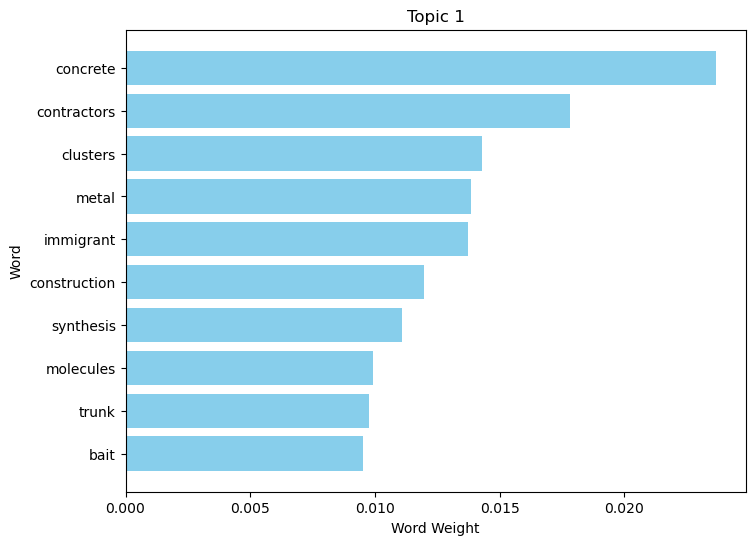

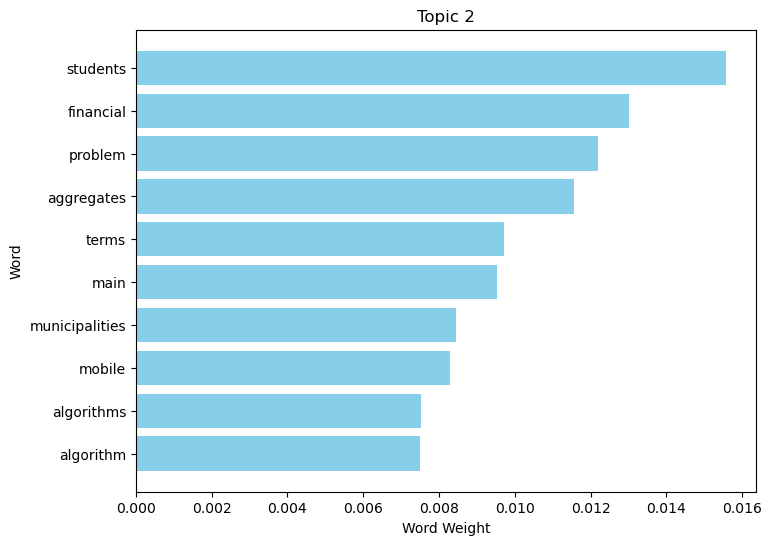

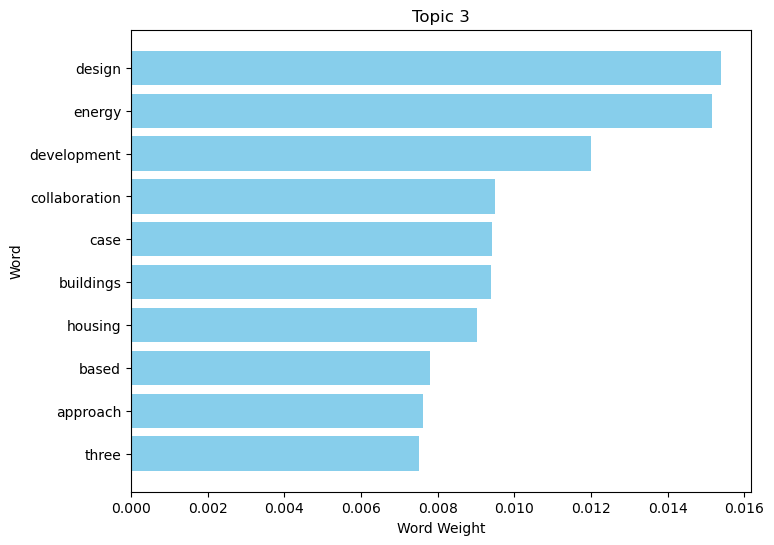

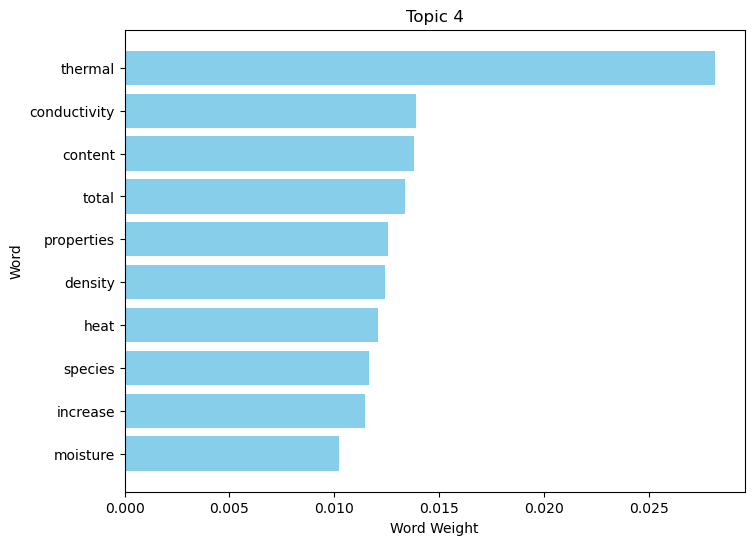

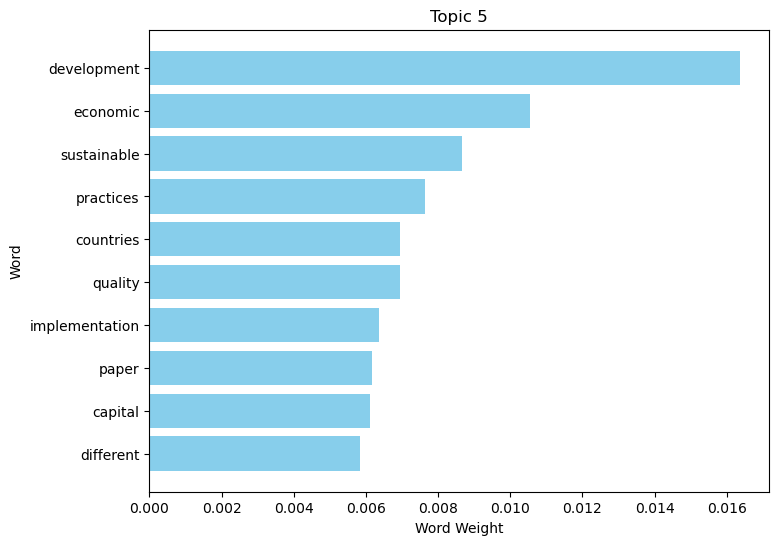

...

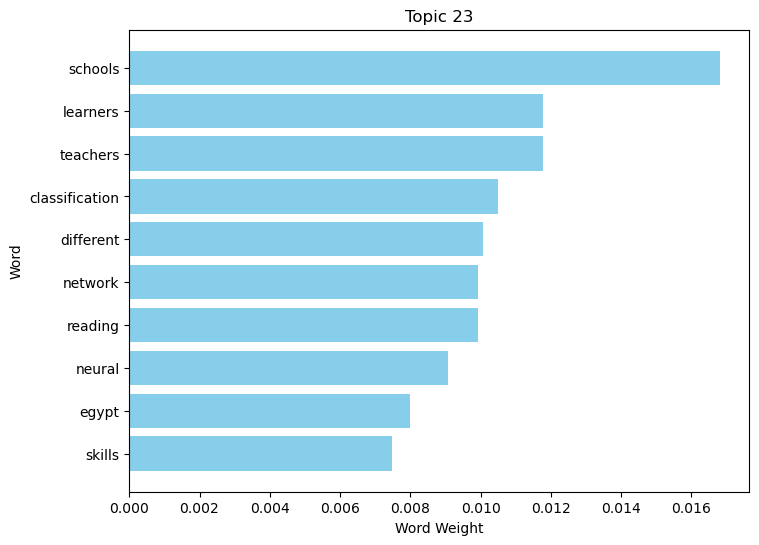

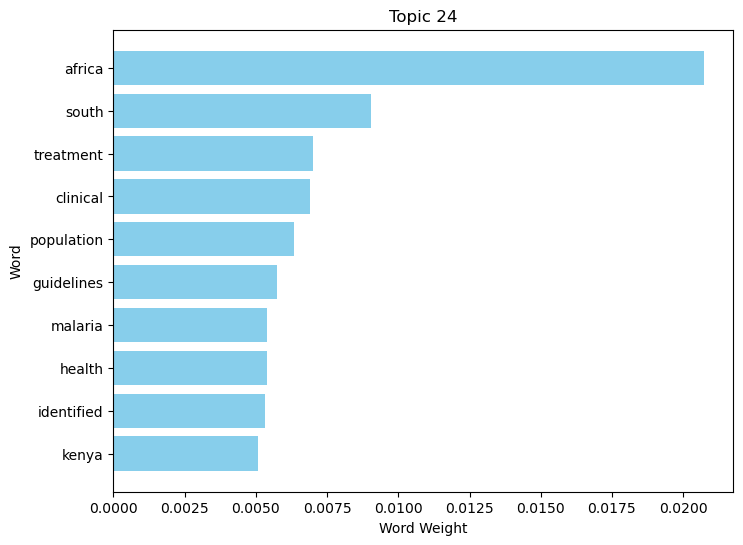

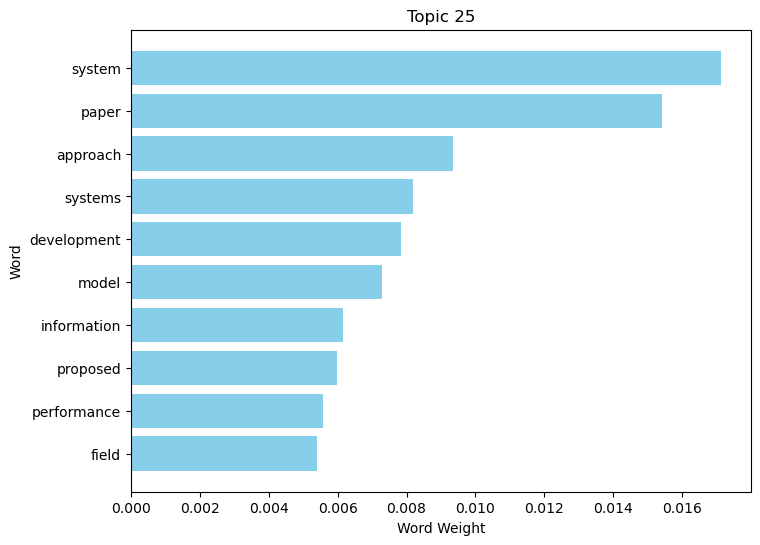

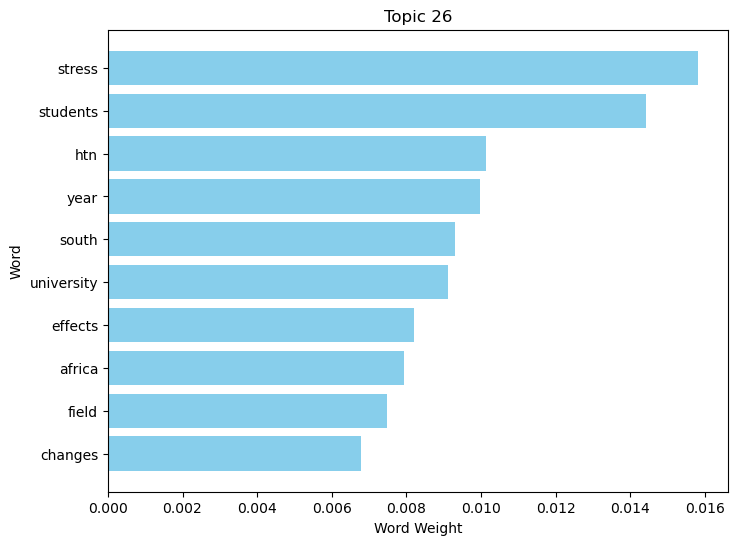

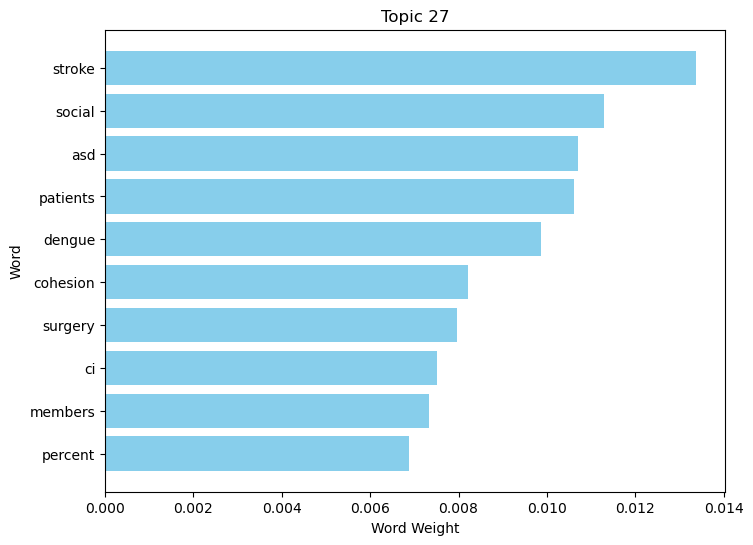

In [45]:
import matplotlib.pyplot as plt

# Function to plot top N words for each topic
def plot_top_words(lda_model, num_words=10):
    topics = lda_model.show_topics(formatted=False, num_topics=-1, num_words=num_words)
    for topic_id, topic in topics:
        words = [word for word, _ in topic]
        weights = [weight for _, weight in topic]
        plt.figure(figsize=(8, 6))
        plt.barh(words, weights, color='skyblue')
        plt.title(f"Topic {topic_id + 1}")
        plt.xlabel('Word Weight')
        plt.ylabel('Word')
        plt.gca().invert_yaxis()
        
        # Save the plot
        plt.savefig(f"Topic_{topic_id + 1}_BarChart.jpg")
        
        # Show the plot
        plt.show()

# Plot top words for each topic
plot_top_words(lda_model)



# TOPIC NETWORK

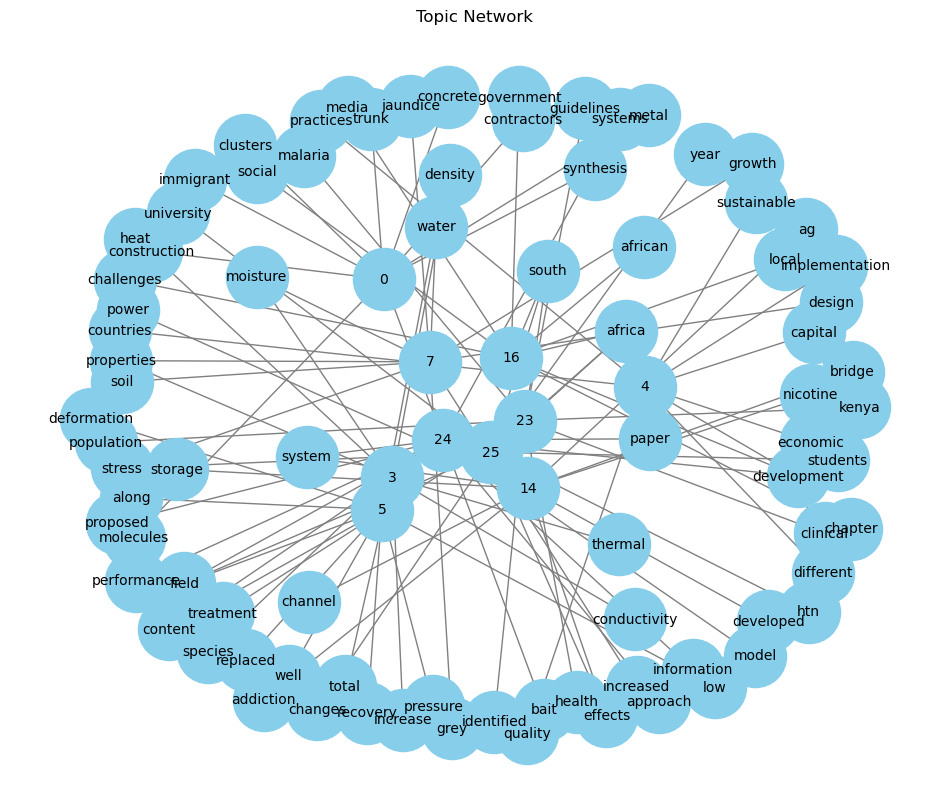

In [46]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx  # Add this line
from mpl_toolkits.mplot3d import Axes3D

# Function to plot topic network
def plot_topic_network(lda_model):
    topics = lda_model.show_topics(formatted=False)
    G = nx.Graph()
    for i, topic in topics:
        for word, weight in topic:
            G.add_edge(i, word, weight=weight)
    plt.figure(figsize=(12, 10))
    pos = nx.spring_layout(G, k=0.2)
    ax = plt.gca()  # Get current axis
    nx.draw(G, pos, node_color='skyblue', with_labels=True, node_size=2000, font_size=10, edge_color='gray', ax=ax)
    plt.title('Topic Network')
    plt.show()

# Plot topic network
plot_topic_network(lda_model)


# DOCUMENT-TOPIC DISTRIBUTION

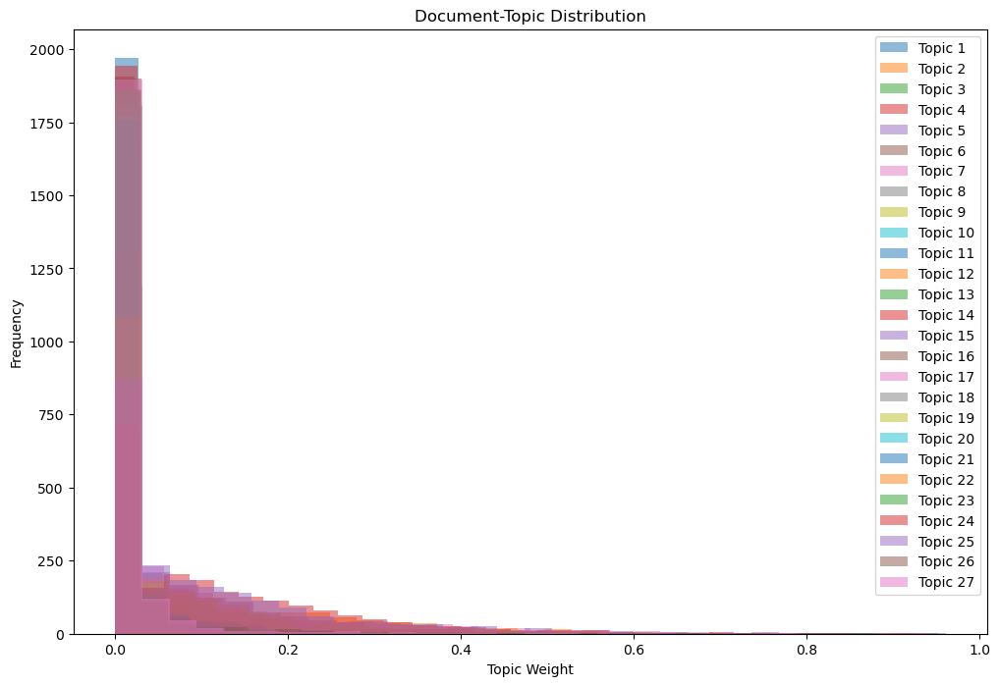

In [47]:

# Function to plot document-topic distribution
import numpy as np

def plot_document_topic_distribution(lda_model, corpus):
    document_topics = [lda_model.get_document_topics(doc) for doc in corpus]
    topic_weights = np.zeros((len(corpus), lda_model.num_topics))
    for i, doc_topics in enumerate(document_topics):
        for topic, weight in doc_topics:
            topic_weights[i, topic] = weight
    plt.figure(figsize=(12, 8))
    for i in range(lda_model.num_topics):
        plt.hist(topic_weights[:, i], bins=30, alpha=0.5, label=f"Topic {i+1}")
    plt.title('Document-Topic Distribution')
    plt.xlabel('Topic Weight')
    plt.ylabel('Frequency')
    plt.legend()
    plt.show()

# Plot document-topic distribution
plot_document_topic_distribution(lda_model, corpus)


# HEATMAP

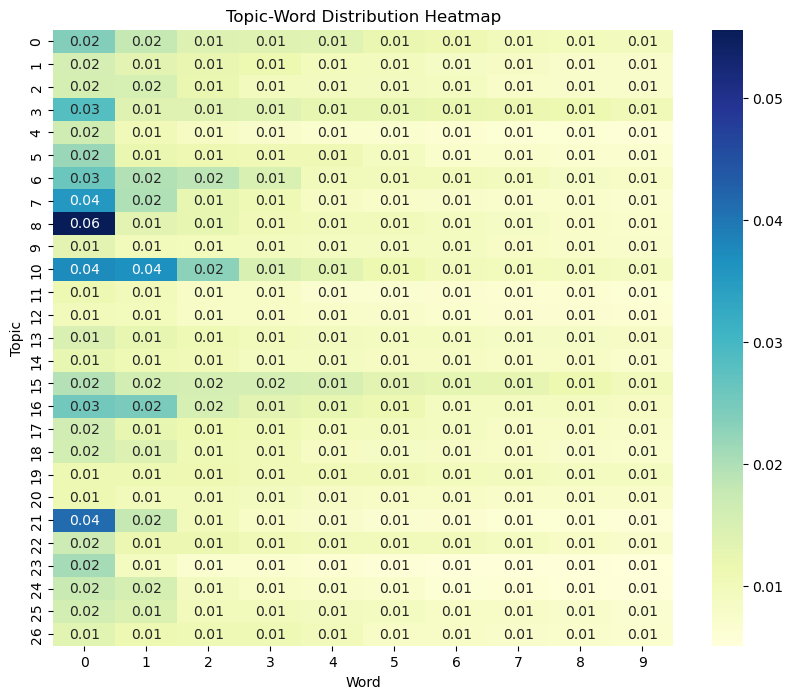

In [48]:
import seaborn as sns
import numpy as np

# Function to plot topic-word distribution heatmap
def plot_topic_word_heatmap(lda_model, num_words=10):
    topics = lda_model.show_topics(formatted=False, num_topics=-1, num_words=num_words)
    word_weights = []
    for _, topic in topics:
        word_weights.append([weight for _, weight in topic])
    plt.figure(figsize=(10, 8))
    sns.heatmap(word_weights, cmap='YlGnBu', annot=True, fmt=".2f")
    plt.title('Topic-Word Distribution Heatmap')
    plt.xlabel('Word')
    plt.ylabel('Topic')
    plt.show()

# Plot topic-word distribution heatmap
plot_topic_word_heatmap(lda_model)

# 3D MODEL

C:\Users\Derek\AppData\Local\Temp\ipykernel_4824\3415188629.py:18: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  colormap = plt.cm.get_cmap('viridis', len(topic_weights['Cluster Label'].unique()))  # Adjust colormap as needed


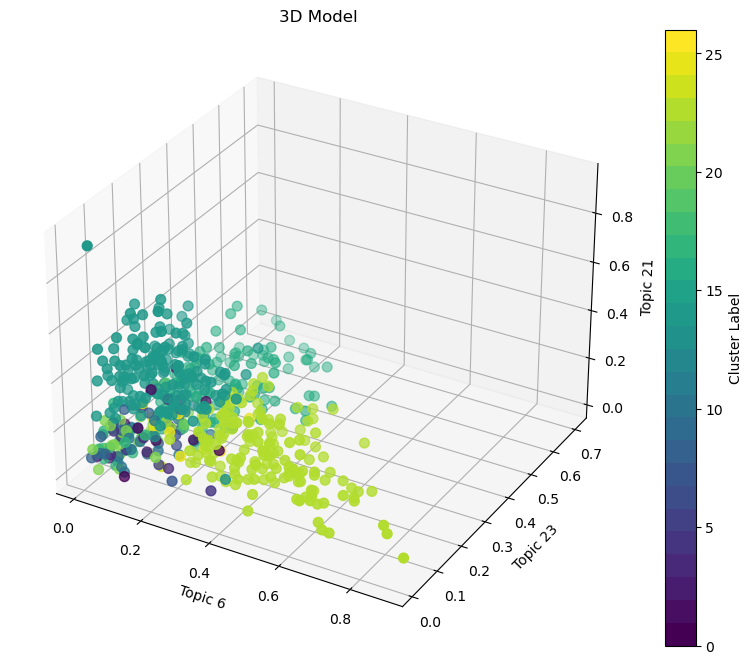

In [61]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

def plot_3d_model(lda_model, corpus):
    topic_weights = lda_model.get_document_topics(corpus)
    topic_weights = pd.DataFrame([{f"Topic {i}": weight for i, weight in doc} for doc in topic_weights])
    topic_weights['Cluster Label'] = topic_weights.idxmax(axis=1)
    
    # Assign numerical values to cluster labels for color mapping
    topic_weights['Cluster Label'] = topic_weights['Cluster Label'].astype('category')
    topic_weights['Cluster Label'] = topic_weights['Cluster Label'].cat.codes
    
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')
    
    # Use a colormap for color mapping
    colormap = plt.cm.get_cmap('viridis', len(topic_weights['Cluster Label'].unique()))  # Adjust colormap as needed
    
    # Scatter plot with colors mapped from the colormap
    scatter = ax.scatter(topic_weights['Topic 6'], 
                         topic_weights['Topic 23'], 
                         topic_weights['Topic 21'], 
                         c=topic_weights['Cluster Label'], 
                         cmap=colormap, 
                         s=50)
    
    ax.set_xlabel('Topic 6')
    ax.set_ylabel('Topic 23')
    ax.set_zlabel('Topic 21')
    ax.set_title('3D Model')
    
    # Add color bar
    cbar = plt.colorbar(scatter)
    cbar.set_label('Cluster Label')
    
    # Save the map
    plt.savefig("Topic_weights.jpg")
    
    plt.show()

# Call the function with the LDA model and corpus
plot_3d_model(lda_model, corpus)
